-------------------------------------------------------------------------------------------------------
# TARE MODEL SCENARIO: 2025 Reference Case
-------------------------------------------------------------------------------------------------------
ResStock 2022 Release (EUSS) Post-Retrofit Measure Packages, Heat Pump Adoption: MP3 and MP4
- MP3: Min-efficiency, single-stage ASHP (15 SEER1, 9 HSPF1) --> (16 SEER1, 9.5 HSPF1) for ENERGY STAR
- MP4: High-efficiency, variable-speed ASHP (24-29.3 SEER1, 14 HSPF1)

ResStock 2025 Release Post-Retrofit Measure Package, Dual-Fuel Heat Pump Adoption: MP5
- MP5: Dual-fuel heat pump (15.2 SEER2, 7.8 HSPF2) with a gas backup furnace that heats the home below 35 F

One release per run, chosen with the environment variable TARE_RESSTOCK_RELEASE ('2022.1.1' when unset).

Reference Case Data and Assumptions:
- AEO2026 fuel price projections
- AEO2026 degree-day factors
- Cambium 2024 MidCase electricity grid
- Single scenario: '2025 Reference Case'


In [1]:
# =============================================================================
# IMPORTS
# =============================================================================
import os
from IPython import get_ipython
from datetime import datetime
import logging
import time

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Project configuration
import sys
sys.path.insert(0, os.path.abspath(".."))
from config import PROJECT_ROOT

# Model constants - explicit imports for clarity
from cmu_tare_model.constants import (
    VERBOSE,
    SCC_ASSUMPTIONS,
    REMDB_COST_SCENARIO_KEYS,
    VALID_MENU_MPS,
    BLDG_ID_COL,
    TIMESTAMP_COL,
    ELEC_TOTAL_COL,
    BSQ_ELEC_COL,
    TEST_FIPS,
    SEASONS
)
from cmu_tare_model.constants import PRIVATE_DISCOUNT_RATE_SHORT_KEYS

# Column name builders
from cmu_tare_model.utils.column_names import (
    NPV_CASE_CATEGORIES,
    BASE_CASE_NPV_CASE
)
from cmu_tare_model.grid_impact.peak_load_functions import (
    find_adoption_column,
    compute_county_scenario_profile,
    plot_county_demand_grid,
    compute_county_scenario_profile_seasonal,
    peak_dicts_to_table
)

# Data loading utility
from cmu_tare_model.utils.load_exported_results_to_df import load_model_run_output, load_measure_package_data

# =============================================================================
# MATPLOTLIB/SEABORN CONFIGURATION
# =============================================================================
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = 'Arial'
plt.close('all')
%matplotlib inline

sns.set_theme(font='sans-serif', style='white')

# =============================================================================
# PROJECT ROOT AND TIMESTAMP SETUP
# =============================================================================
# Get the current datetime
start_time = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")

# Format the name of the exported results file using the location ID
result_export_time = datetime.now()
model_run_date_time = result_export_time.strftime("%Y-%m-%d_%H-%M")

print(f"""
PROJECT_ROOT: {PROJECT_ROOT}

Start Time: {start_time}
Model Run Timestamp: {model_run_date_time}

Active Measure Packages: {VALID_MENU_MPS}
Active Capital Cost Scenarios: {REMDB_COST_SCENARIO_KEYS}
Active SCC Assumptions: {SCC_ASSUMPTIONS}
Active Discount Rates: {PRIVATE_DISCOUNT_RATE_SHORT_KEYS}

Note: DataFrames contain columns for ALL active cost scenarios.

""")

Project root directory: c:\Users\tamar\Documents\Research\cmu-tare-model

PROJECT_ROOT: c:\Users\tamar\Documents\Research\cmu-tare-model

Start Time: 2026-10-19_15-52-22
Model Run Timestamp: 2026-10-19_15-52

Active Measure Packages: [0, 3, 4]
Active Capital Cost Scenarios: ['v4MID']
Active SCC Assumptions: ['lower', 'central', 'upper']
Active Discount Rates: ['fixed_base']

Note: DataFrames contain columns for ALL active cost scenarios.




In [2]:
# Select whether to begin new run or visualize existing model outputs
while True:
    try:
        start_new_model_run = str(input("""
Would you like to begin a new simulation or visualize output results from a previous model run? Please enter one of the following:
Y. I'd like to start a new model run.
N. I'd like to visualize output results from a previous model run.""")).upper()

        print(f"Enter the following input: {start_new_model_run}")

        if start_new_model_run == 'Y':
            print(f"Formatted date for use in file name: {model_run_date_time}")

            # Relative path to the file from the project root
            relative_path = os.path.join("cmu_tare_model", "model_scenarios", "tare_run_simulation_v3_1.ipynb")

            # Construct the absolute path to the file
            file_path = os.path.join(PROJECT_ROOT, relative_path)
            print(f"File path: {file_path}")

            # Storing Result Outputs in output_results folder
            output_folder_path = os.path.join(PROJECT_ROOT, "cmu_tare_model", "output_results")
            print(f"Result outputs will be exported here: {output_folder_path}")

            # On Windows, to avoid any path-escape quirks, convert backslashes to forward slashes
            file_path = file_path.replace("\\", "/")

            print(f"Running file: {file_path}")

            # iPthon magic command to run a .py file and import variables into the current IPython session
            if os.path.exists(file_path):
                get_ipython().run_line_magic('run', f'-i {file_path}')  # If your path has NO spaces, no quotes needed.
            else:
                print(f"File not found: {file_path}")

            break  # Exit the loop if input is 'Y'
            
        elif start_new_model_run == 'N':
            # Enter the date time of the model run in the following format: YYYY-MM-DD_HH-MM
            model_run_date_time = str(input("Enter the date time of the model run in the following format YYYY-MM-DD_HH-MM: "))
            location_id = str(input("Enter the location ID used in the model run (e.g., 'National' or 'PA'): "))
            
            # Load model run results
            print(f"Loading model run results for location ID: {location_id} and timestamp: {model_run_date_time}")

            # Storing Result Outputs in output_results folder
            output_folder_path = os.path.join(PROJECT_ROOT, "cmu_tare_model", "output_results")
            print(f"Past model run results will be loaded from here: {output_folder_path}")
            
            break  # Exit the loop if input is 'N'
        
        else:
            print("Invalid input. Please enter 'Y' or 'N'.")
    
    except Exception as e:
        print("An error occurred:", e)
        print("Please try again.")

Enter the following input: N
Loading model run results for location ID: CO and timestamp: 2026-10-19_13-41
Past model run results will be loaded from here: c:\Users\tamar\Documents\Research\cmu-tare-model\cmu_tare_model\output_results


In [3]:
if VERBOSE:
    print(f"""
    ====================================================================================================================================================================
    LOAD SCENARIO DATA
    ====================================================================================================================================================================
    The load_model_run_output function loads scenario data from a specified folder and date. Additional details are provided below:
        
    Documentation for the load_model_run_output function:
    {load_model_run_output.__doc__}

    -----------------------------------------------------------------------------------------------
    LOADING SCENARIO DATA ...

    These parameters are common to all function calls:
    Output folder path: {output_folder_path}
    Model run date time: {model_run_date_time}
    """)


    LOAD SCENARIO DATA
    The load_model_run_output function loads scenario data from a specified folder and date. Additional details are provided below:

    Documentation for the load_model_run_output function:
    Load model run results from CSV files (reverse of export_model_run_output).

    This function loads DataFrame results from CSV files organized by result type.
    It mirrors the export_model_run_output() function exactly, using the same
    parameters to construct the correct file path.

    Args:
        results_category: Category of results being loaded. Valid options:
            - 'summary_baseline': Baseline summary results
            - 'summary': Retrofit summary results (requires discount_rate)
            - 'damages_climate_IRA', 'damages_climate_noIRA': Climate damages
            - 'fuel_costs_IRA', 'fuel_costs_noIRA': Fuel costs
        menu_mp: Measure package identifier (0 for baseline, VALID_MENU_MPS for retrofits).
        output_folder_path: Base direct

-------------------------------------------------------------------------------------------------------
# LOAD MODEL RUN OUTPUT FOR ANALYSIS + VISUALS
-------------------------------------------------------------------------------------------------------

In [4]:
# ========== Baseline Scenario: Measure Package 0 (MP0) ==========
menu_mp = 0

df_outputs_baseline_home = load_model_run_output(
    results_category='summary_baseline',
    menu_mp=menu_mp,
    output_folder_path=output_folder_path,
    location_id=location_id,
    results_export_formatted_date=model_run_date_time,
    use_chunked_loading=True,
    chunk_size=10000
)

# The study sample, rebuilt from the include_sample flag the run saved. County
# demand, peaks, and custom weighting use it, since they read ResStock directly.
from cmu_tare_model.constants import RESSTOCK_RELEASE_THIS_RUN
from cmu_tare_model.energy_consumption_and_metadata.study_sample import (
    build_tare_sample_ids,
)
TARE_SAMPLE_IDS = build_tare_sample_ids(
    df_outputs_baseline_home, RESSTOCK_RELEASE_THIS_RUN)
print(f"Study sample: {len(TARE_SAMPLE_IDS['all']):,} rdu in "
      f"{len(TARE_SAMPLE_IDS['by_county']):,} counties")

# ========== Load Measure Packages in VALID_MENU_MPS ==========
NON_BASELINE_MPS = [mp for mp in VALID_MENU_MPS if mp != 0]

# Convenience mapping for downstream code
DATAFRAMES_BY_MP = {}

for mp in NON_BASELINE_MPS:
    DATAFRAMES_BY_MP[mp] = load_measure_package_data(
        mp, output_folder_path, location_id, model_run_date_time
    )

print(f"\nLoaded measure packages: {list(DATAFRAMES_BY_MP.keys())}")

Loading baseline_results_CO_2026-10-19_13-41.csv in chunks of 10,000 rows...
  Successfully combined 1 chunks into DataFrame with shape (6783, 81)
Loaded: baseline_results_CO_2026-10-19_13-41.csv
Shape: (6783, 81)

Study sample: 3,406 rdu in 62 counties
Loading MP3 data...
  fixed_base: Loading mp3_results_CO_2026-10-19_13-41.csv in chunks of 10,000 rows...
  Successfully combined 1 chunks into DataFrame with shape (6783, 215)
Loaded: mp3_results_CO_2026-10-19_13-41.csv
Shape: (6783, 215)

[OK]
MP3 loading complete!

Loading MP4 data...
  fixed_base: Loading mp4_results_CO_2026-10-19_13-41.csv in chunks of 10,000 rows...
  Successfully combined 1 chunks into DataFrame with shape (6783, 215)
Loaded: mp4_results_CO_2026-10-19_13-41.csv
Shape: (6783, 215)

[OK]
MP4 loading complete!


Loaded measure packages: [3, 4]


-------------------------------------------------------------------------------------------------------
# ECONOMIC ADOPTION POTENTIAL
-------------------------------------------------------------------------------------------------------

## Does the heat pump pay for itself?

An **economic adopter** is a home where the heat pump's extra upfront cost is
recovered from energy-bill savings alone -- no climate or health benefit is
needed to justify the investment.

**The rule:** a home is an economic adopter if its incremental private
NPV >= 0. Break-even counts as adoption.

| Value | Meaning |
|-------|---------|
| `True` or 1  | Heat pump covers its incremental cost (or better) from bill savings |
| `False` or 0 | Valid home that cannot recover the incremental cost from savings alone |
| `NaN`   | Excluded: invalid baseline fuel/tech or not in this measure package |

Climate emissions and damages are computed elsewhere and reported as outcomes,
not as inputs to this decision.

In [5]:
# =============================================================================
# ECONOMIC ADOPTION -- setup: imports, parameters, and shared inputs
# =============================================================================
# Transported from calculate_postTARE_am_kpis_demand_bill_savings. Column names
# use the nine-case NPV_CASE_CATEGORIES scheme; there is no WTP or cost-scenario
# token in adopter column names.
import geopandas as gpd
from matplotlib.colors import Normalize
from cmu_tare_model.constants import CAPITAL_COST_VALIDATION, GRID_IMPACT_ANALYSIS
from cmu_tare_model.adoption_potential.determine_economic_adoption_potential import (
    economic_adoption_decision,
)
from cmu_tare_model.utils.modeling_params import define_scenario_params
from cmu_tare_model.utils.column_names import create_adoption_col
from cmu_tare_model.adoption_kpis.data_loading import load_euss_baseline
from cmu_tare_model.adoption_kpis.compute_adoption_rate import compute_adoption_rate
from cmu_tare_model.adoption_kpis.visualize_geospatial_data import (
    plot_national_county_choropleth,
    plot_national_county_change_map,
)
from cmu_tare_model.adoption_kpis.data_loading import COUNTY_SHAPEFILE_PATH
from cmu_tare_model.adoption_potential.data_processing.visuals_adoption_dotplot import (
    plot_econ_adoption_dotplot_figure,
    REPLACEMENT_CREDIT_MARKERS,
    build_replacement_credit_legend_handles,
    build_rebate_policy_scenario_legend_handles,
    REBATE_POLICY_SCENARIO_MARKERS,
)

# Base-case parameters. The economic-adopter column name encodes these:
# e.g. 'ref2025_mp3_heatingLCC_coolingLCC_sub_econ_adopter_fixed_base'.
_POLICY = '2025 Reference Case'
_DISCOUNT_COL = 'private_discount_rate_fixed_base'
_COST = 'v4MID'                 # REMDB v4 midpoint (retained for API compat)
discount_rate = 'fixed_base'    # 7% fixed discount rate
SAVE_FIGURES = True             # Set False to skip writing figure files to disk
FIGURE_DPI = 600                # Resolution for saved figures (matches other savefig calls)

# The adoption analysis runs on every loaded non-baseline measure package.
selected_mps = NON_BASELINE_MPS
HEATING_MEASURE_PACKAGES = selected_mps

# Equipment subtitles used as panel/map titles. Covers this notebook's MP set.
HEATING_MP_SUBTITLES = {
    # 3: 'Single-stage, min-efficiency ASHP (16 SEER1, 9.5 HSPF1)',
    # 4: 'Variable-speed, high-efficiency ASHP (24-29.3 SEER1, 13-14 HSPF1)',
    3: 'Single-stage, minimum-efficiency heat pump',
    4: 'Variable-speed, high-efficiency heat pump',
    # ResStock 2025.1 Upgrade 05. 3 and 4 above are the 2022.1.1 packages;
    # the 2025.1 Upgrades 03 and 04 will need titles of their own.
    5: 'Dual-fuel heat pump with gas backup furnace',
    8: 'Whole-Home Electrification (High Efficiency)',
    9: 'Whole-Home Electrification + Basic Enclosure Upgrade',
    10: 'Whole-Home Electrification + Enhanced Enclosure Upgrade',
}

# EUSS baseline provides household weights for county adoption-rate weighting.
df_baseline = load_euss_baseline()
print(f"Baseline: {len(df_baseline):,} occupied SF rdu")

# County shapefile for the adoption-rate choropleth. Missing shapefile is a
# warning, not an error -- the choropleth cell is skipped if it is unavailable.
gdf_counties_raw = None
try:
    gdf_counties_raw = gpd.read_file(COUNTY_SHAPEFILE_PATH)
    print(f"[OK] County shapefile loaded: {len(gdf_counties_raw)} features")
except Exception as e:
    print(f"[WARN] County shapefile not loaded: {e}")

        stage  rdu_count  weighted_count  Electricity_pct  Electricity ASHP_pct  Fuel Oil_pct  Natural Gas_pct  Propane_pct
         load     548916    1.329096e+08        28.971464             11.159449      4.686692        47.710761     4.632221
applicability     548916    1.329096e+08        28.971464             11.159449      4.686692        47.710761     4.632221
    occupancy     482597    1.168517e+08        28.427446             10.850047      4.643833        49.013566     4.370520
 housing_type     396252    9.594490e+07        24.547763             10.127646      5.005905        52.224342     5.205021
exclude_AK_HI     396252    9.594490e+07        24.547763             10.127646      5.005905        52.224342     5.205021
Baseline: 396,252 occupied SF rdu
[WARN] County shapefile not loaded: c:\Users\tamar\Documents\Research\cmu-tare-model\cmu_tare_model\data\shapefiles\cb_2021_us_county_500k\cb_2021_us_county_500k.shp: No such file or directory


In [6]:
# Generate the NINE economic-adopter columns (one per NPV case) for each measure
# package. After this cell, every case column exists in the 'fixed_base' frame
# (three scopes x three rebate policy scenarios: unsub, sub, sub_june2026):
#   ref2025_mp{mp}_heatingSavings_coolingLCC_{unsub,sub,sub_june2026}_econ_adopter_fixed_base
#   ref2025_mp{mp}_heatingLCC_coolingSavings_{unsub,sub,sub_june2026}_econ_adopter_fixed_base
#   ref2025_mp{mp}_heatingLCC_coolingLCC_{unsub,sub,sub_june2026}_econ_adopter_fixed_base

for mp in selected_mps:
    df_tare = DATAFRAMES_BY_MP[mp]['fixed_base']
    scenario_prefix = define_scenario_params(mp, _POLICY)[0]
    expected_adopter_cols = [
        create_adoption_col(scenario_prefix, npv_case, '_fixed_base')
        for npv_case in NPV_CASE_CATEGORIES
    ]
    missing_cols = [c for c in expected_adopter_cols if c not in df_tare.columns]
    if missing_cols:
        df_econ = economic_adoption_decision(
            df_tare,
            menu_mp=mp,
            policy_scenario=_POLICY,
            discount_rate_col_name=_DISCOUNT_COL,
            cost_scenario=_COST,
            verbose=False,
        )
        # Copy only newly created columns back into the canonical frame.
        new_cols = [c for c in df_econ.columns if c not in df_tare.columns]
        for col in new_cols:
            DATAFRAMES_BY_MP[mp]['fixed_base'][col] = df_econ[col]
        print(f"[OK] MP{mp}: {len(new_cols)} econ-adopter columns added")
    else:
        print(f"[SKIP] MP{mp}: all economic-adopter columns already present")

print("\n[OK] Economic-adopter columns present for all selected MPs")

-- Scenario: 2025 Reference Case (mp3) --
[SKIP] MP3: all economic-adopter columns already present
-- Scenario: 2025 Reference Case (mp4) --
[SKIP] MP4: all economic-adopter columns already present

[OK] Economic-adopter columns present for all selected MPs


ASHP upgrade population:      MP3 3,406 | MP4 3,406
Central AC replacement pop.:  MP3 2,730 | MP4 2,730
NG Furnace replacement pop.:  MP3 2,572 | MP4 2,572
Saved: c:\Users\tamar\Documents\Research\cmu-tare-model\figures\capital_cost_consumption_size_distributions.png / .pdf


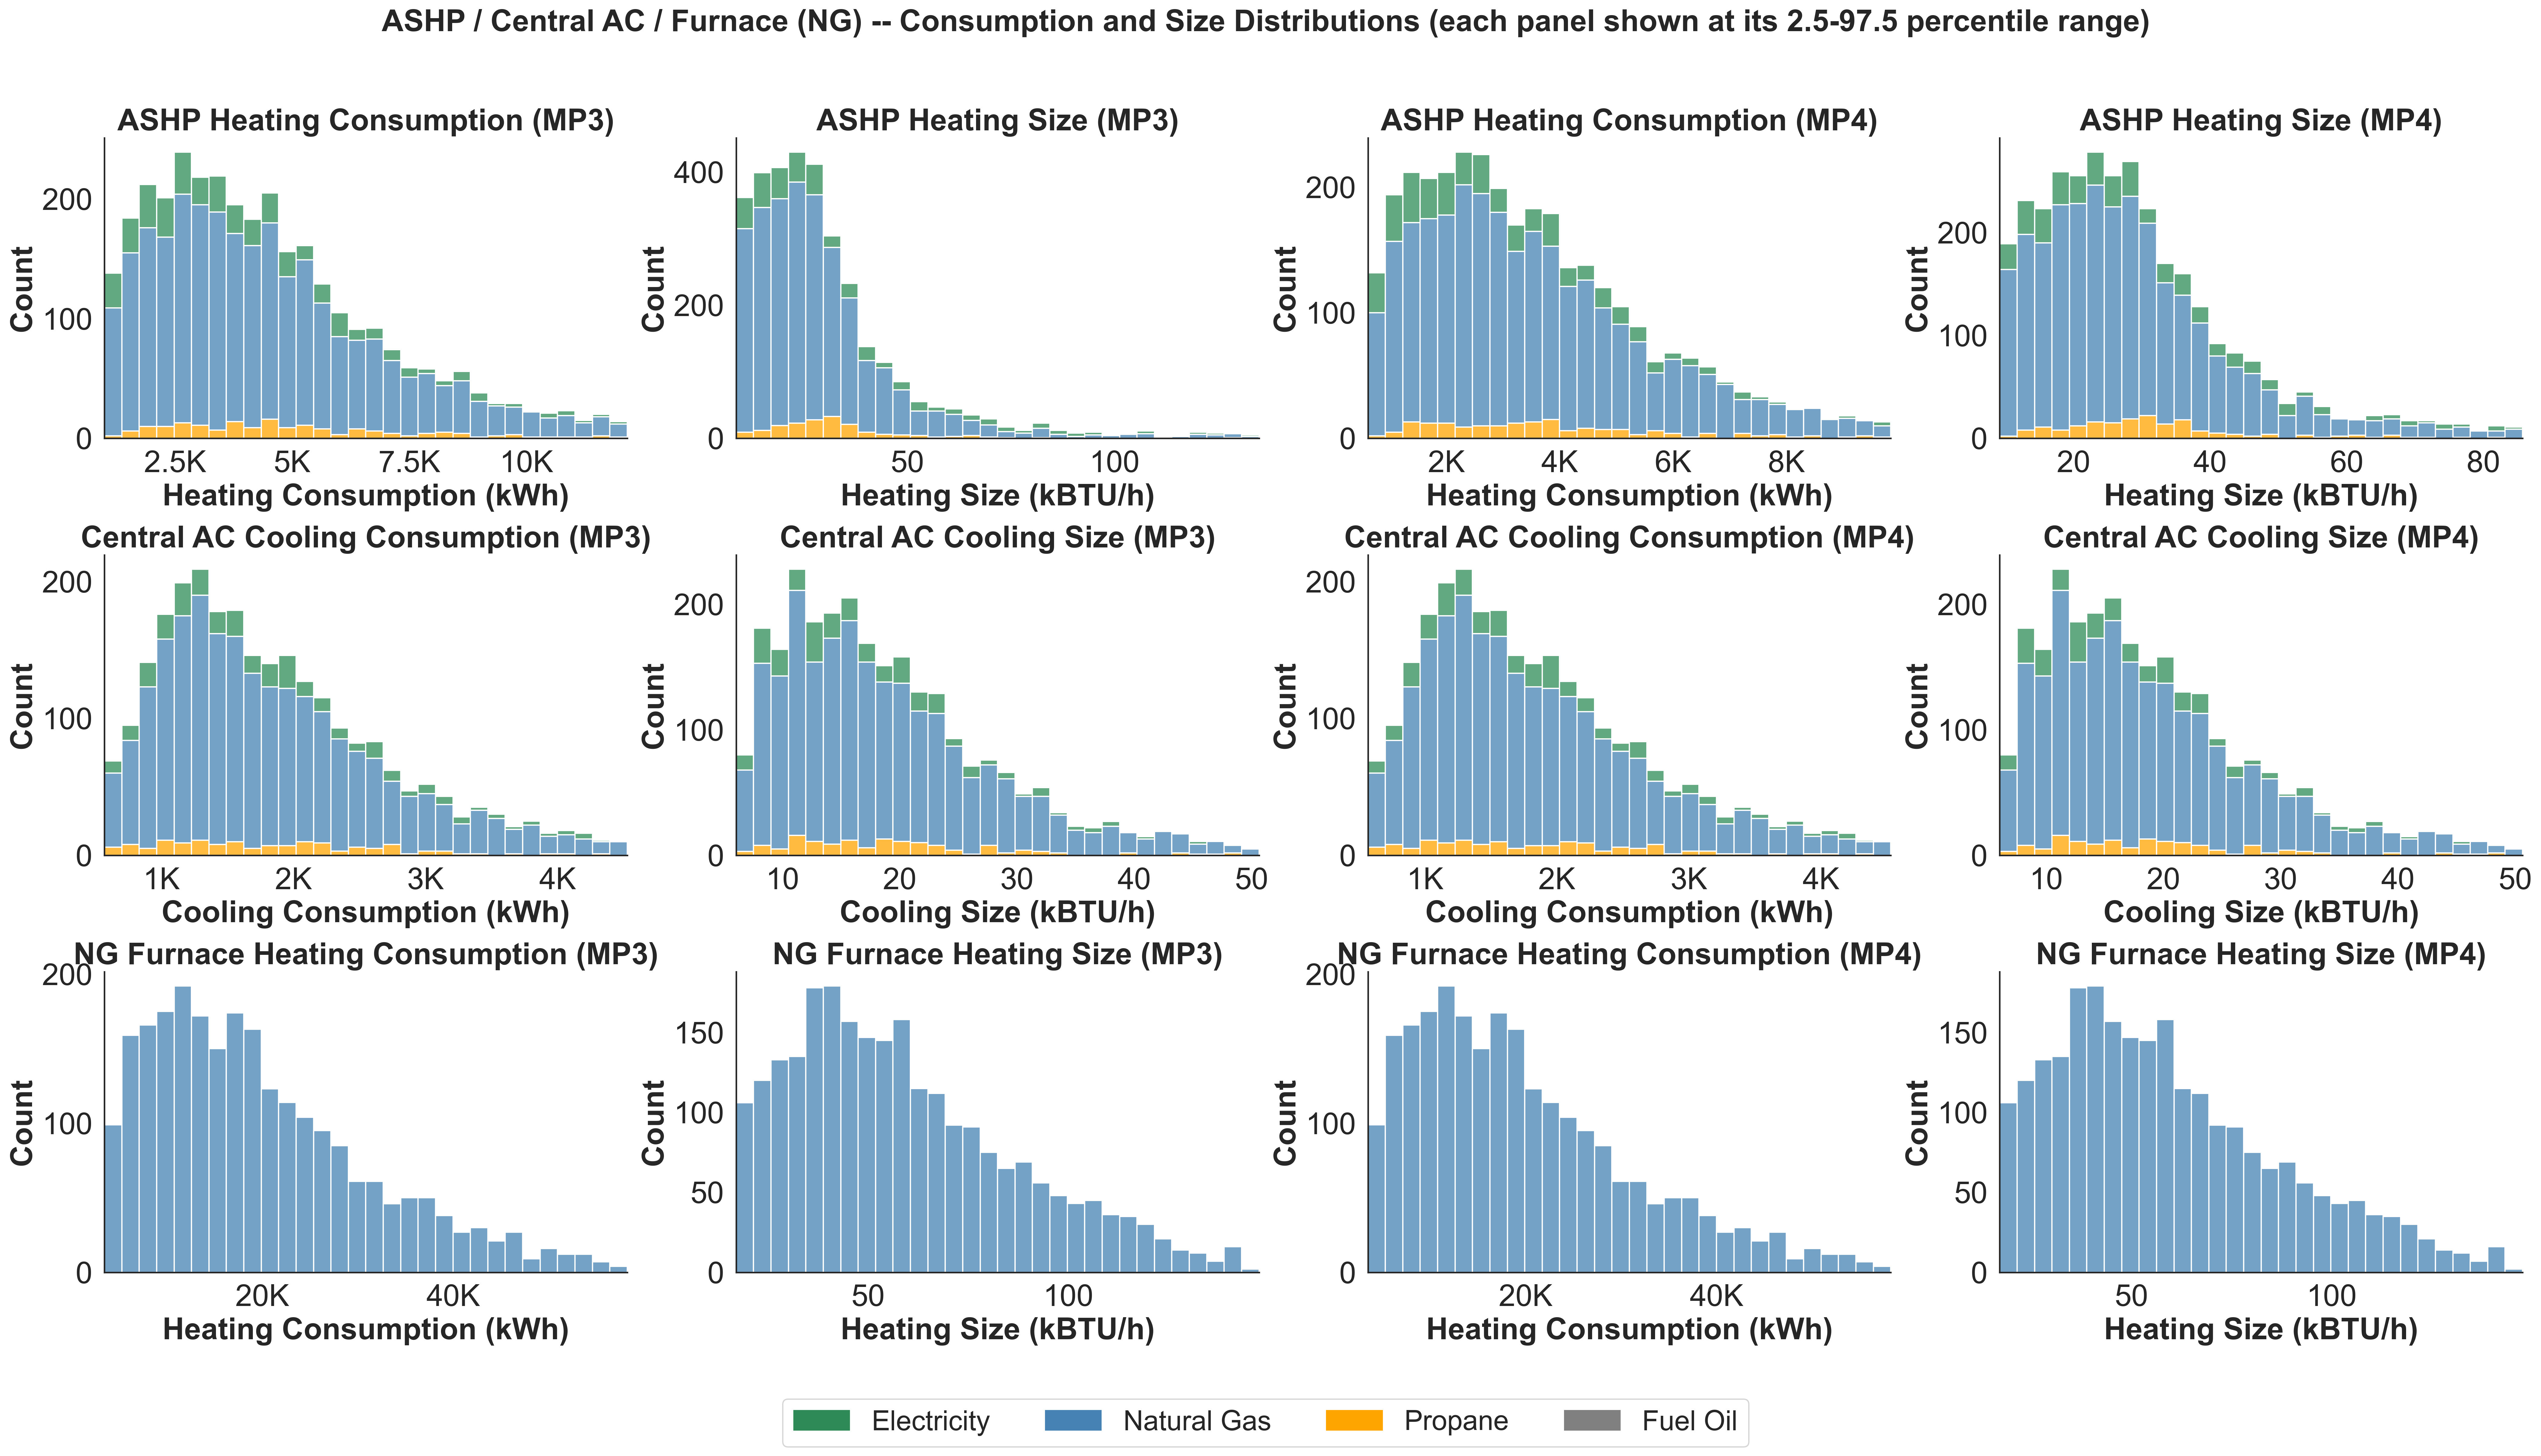


##############################################################################################################
#  CAPITAL COST VALIDATION: Equipment-Level Disaggregation (MP3)
#  Active cost scenarios: ['v4MID']
#  rdu in DataFrame: 6,783 | in the study sample: 3,406
##############################################################################################################

  Central AC — Centrally Ducted (Cooling Replacement)
  Cost type: cooling replacement (like-for-like Central AC)
  Filter: hvac_cooling_type = Central AC
  SEER bins: cooling_replacement_pm2_euss (floored efficiency, see clamping summary)
  Costs: computed using floored efficiency (see Section 5 of protocol)
  v3 note: No v3 data exists for cooling replacement — v3 columns show N/A

  Total rdu matching filter: 2,730
  Outliers excluded from bins:
    Capacity  < 1.5 tons: 1,477 rdu
    Capacity >= 10.5 tons: 0 rdu
    SEER  < 12.5: 0 rdu
    SEER >= 30.5: 0 rdu

  Efficiency floor impact on SEER 15 bin composi

In [7]:
# =============================================================================
# CAPITAL COST VALIDATION
# =============================================================================

# TODO: Make file paths and names configurable, not hard-coded. 
# These capital-cost cells compare MP3 with MP4: they read DATAFRAMES_BY_MP[3]
# and [4] and the ref2025_mp3_ / ref2025_mp4_ columns. So they run only for
# ResStock 2022.1.1 with both packages loaded.
RUN_MP3_MP4_COST_VALIDATION = (
    CAPITAL_COST_VALIDATION
    and RESSTOCK_RELEASE_THIS_RUN == '2022.1.1'
    and {3, 4} <= set(VALID_MENU_MPS)
)
if RUN_MP3_MP4_COST_VALIDATION:
    # Perform capital cost validation using the validate_capital_costs module.
    # Builds the ASHP/Central AC/Furnace consumption-and-size distribution
    # figure and the REMDB v4MID disaggregation workbook (ASHP upgrade,
    # Central AC replacement, NG Furnace replacement) for MP3 and MP4.
    from cmu_tare_model.utils.validate_capital_costs import (
        build_ashp_primary_vs_total_consumption_figure,
        build_capital_cost_disaggregation_workbook,
        build_capital_cost_distribution_figure,
        build_furnace_ashp_metric_comparison_figure,
        run_capital_cost_validation,
    )

    df_mp3_ccv = DATAFRAMES_BY_MP[3]['fixed_base']
    df_mp4_ccv = DATAFRAMES_BY_MP[4]['fixed_base']

    # Consumption/size distributions, color-coded by baseline heating fuel.
    fig_capital_cost_dist = build_capital_cost_distribution_figure(df_mp3_ccv, df_mp4_ccv)
    if SAVE_FIGURES:
        fig_path_base = os.path.join(PROJECT_ROOT, 'figures', 'capital_cost_consumption_size_distributions')
        fig_capital_cost_dist.savefig(f'{fig_path_base}.png', dpi=FIGURE_DPI, bbox_inches='tight')
        fig_capital_cost_dist.savefig(f'{fig_path_base}.pdf', dpi=FIGURE_DPI, bbox_inches='tight')
        print(f"Saved: {fig_path_base}.png / .pdf")
    plt.show()

    # REMDB v4MID disaggregation workbook -- matches the Equipment_Installed_TARE
    # reference workbook's sheet names and block layout, minus its v3 columns.
    results_mp3_ccv = run_capital_cost_validation(df=df_mp3_ccv, menu_mp=3, cost_scenarios=['v4MID'])
    results_mp4_ccv = run_capital_cost_validation(df=df_mp4_ccv, menu_mp=4, cost_scenarios=['v4MID'])
    wb_capital_cost = build_capital_cost_disaggregation_workbook(results_mp3_ccv, results_mp4_ccv)
    
    # TODO: Make file paths and names configurable, not hard-coded.
    # f'Equipment_Installed_TARE_v4MID_current_{model_run_date_time}.xlsx'
    # Past name was r'\Equipment_Installed_TARE_v4MID_current_2026-09-16.xlsx'
    workbook_path = (
        r'C:\Users\jorda\Desktop\CMU\Scott-Trane Externship\Cost Data'
        r'\Equipment_Installed_TARE_v4MID_current_2026-09-16.xlsx'
    )
    # wb_capital_cost.save(workbook_path)
    # print(f"Saved: {workbook_path}")


In [8]:
# County-level economic adoption rate. Uses BASE_CASE_NPV_CASE
# ('heatingLCC_coolingLCC_unsub' -- unsubsidized, both avoided replacements credited).
print(f"\n{'='*60}")
print("Economic Adoption Rate -- 2025 Reference Case")
print(f"{'='*60}")

econ_adoption_rate_results = {}
for mp in selected_mps:
    print(f"\n===== {HEATING_MP_SUBTITLES.get(mp, f'MP{mp}')} =====")
    df_tare = DATAFRAMES_BY_MP[mp]['fixed_base']
    prefix = define_scenario_params(mp, _POLICY)[0]
    adoption_col = create_adoption_col(
        scenario_prefix=prefix,
        npv_case=BASE_CASE_NPV_CASE,
        method_suffix='_fixed_base',
    )
    print(f'  Adoption column: {adoption_col}')
    # adopter_tiers=[True] counts 1.0 (adopter) vs 0.0
    # NaN (excluded) rows are ignored automatically by compute_adoption_rate.
    df_adopt = compute_adoption_rate(
        df_tare,
        adoption_col=adoption_col,
        adopter_tiers=[True],
        geo_level='county',
        df_euss=df_baseline,
        verbose=True,
    )
    econ_adoption_rate_results[mp] = df_adopt

print("\n[OK] Economic adoption rate complete (county-level)")



Economic Adoption Rate -- 2025 Reference Case

===== Single-stage, minimum-efficiency heat pump =====
-- Scenario: 2025 Reference Case (mp3) --
  Adoption column: ref2025_mp3_heatingLCC_coolingLCC_unsub_econ_adopter_fixed_base
Counties with data: 62 / 62
Mean counties adoption rate: 13.4%

===== Variable-speed, high-efficiency heat pump =====
-- Scenario: 2025 Reference Case (mp4) --
  Adoption column: ref2025_mp4_heatingLCC_coolingLCC_unsub_econ_adopter_fixed_base
Counties with data: 62 / 62
Mean counties adoption rate: 14.2%

[OK] Economic adoption rate complete (county-level)


In [9]:
# =============================================================================
# ECONOMIC ADOPTION (Choropleth Map) -- Unsub, heating and cooling LCC
# =============================================================================

# The choropleth is skipped if the county shapefile is unavailable.
if gdf_counties_raw is not None:
    _adopt_cmap = 'Greens'

    # Colorbase 0 to 100% adoption potential. 
    _adopt_norm = Normalize(vmin=0, vmax=100)

    print("\n--- Summary: adoption_rate_pct ---")
    for mp in selected_mps:
        _v = econ_adoption_rate_results[mp]['adoption_rate_pct'].dropna()
        _pct_high = (_v >= 50).mean() * 100
        print(f"  MP{mp}: n={len(_v):,} counties | "
              f"min={_v.min():.1f}% | med={_v.median():.1f}% | "
              f"mean={_v.mean():.1f}% | max={_v.max():.1f}% | "
              f"{_pct_high:.1f}% of counties >= 50% adoption potential")

    # Visualize the county-level economic adoption rate as a choropleth. 
    plot_national_county_choropleth(
        gdf_counties_raw, econ_adoption_rate_results,
        column='adoption_rate_pct',
        title_template=HEATING_MP_SUBTITLES,
        cbar_label='Share of households recovering electrification premium through discounted operational savings (%)',
        cmap=_adopt_cmap, norm=_adopt_norm,
        selected_mps=selected_mps,
        save_figure=SAVE_FIGURES,
        output_filename='county_econ_adoption_rate_combined.png',
    )

    print("[OK] Economic adoption choropleth generated")
else:
    print("[WARN] Adoption choropleth skipped -- county shapefile not available")

[WARN] Adoption choropleth skipped -- county shapefile not available


## Economic Adoption Potential Dotplot
### Sensitivity of Heat Pump Adoption to Replacement Cost Offset Assumptions

-- Scenario: 2025 Reference Case (mp3) --
-- Scenario: 2025 Reference Case (mp3) --
--- MP3 economic adoption summary (National, unsubsidized) ---
  Heating Replacement Cost Offset: 4.7%
  Cooling Replacement Cost Offset: 5.2%
  Heating + Cooling Replacement Cost Offset: 9.2%

-- Scenario: 2025 Reference Case (mp4) --
-- Scenario: 2025 Reference Case (mp4) --
--- MP4 economic adoption summary (National, unsubsidized) ---
  Heating Replacement Cost Offset: 4.8%
  Cooling Replacement Cost Offset: 4.7%
  Heating + Cooling Replacement Cost Offset: 7.7%

[OK] Saved figure6_econ_adoption_dotplot_CO.png / .pdf to c:\Users\tamar\Documents\Research\cmu-tare-model\figures


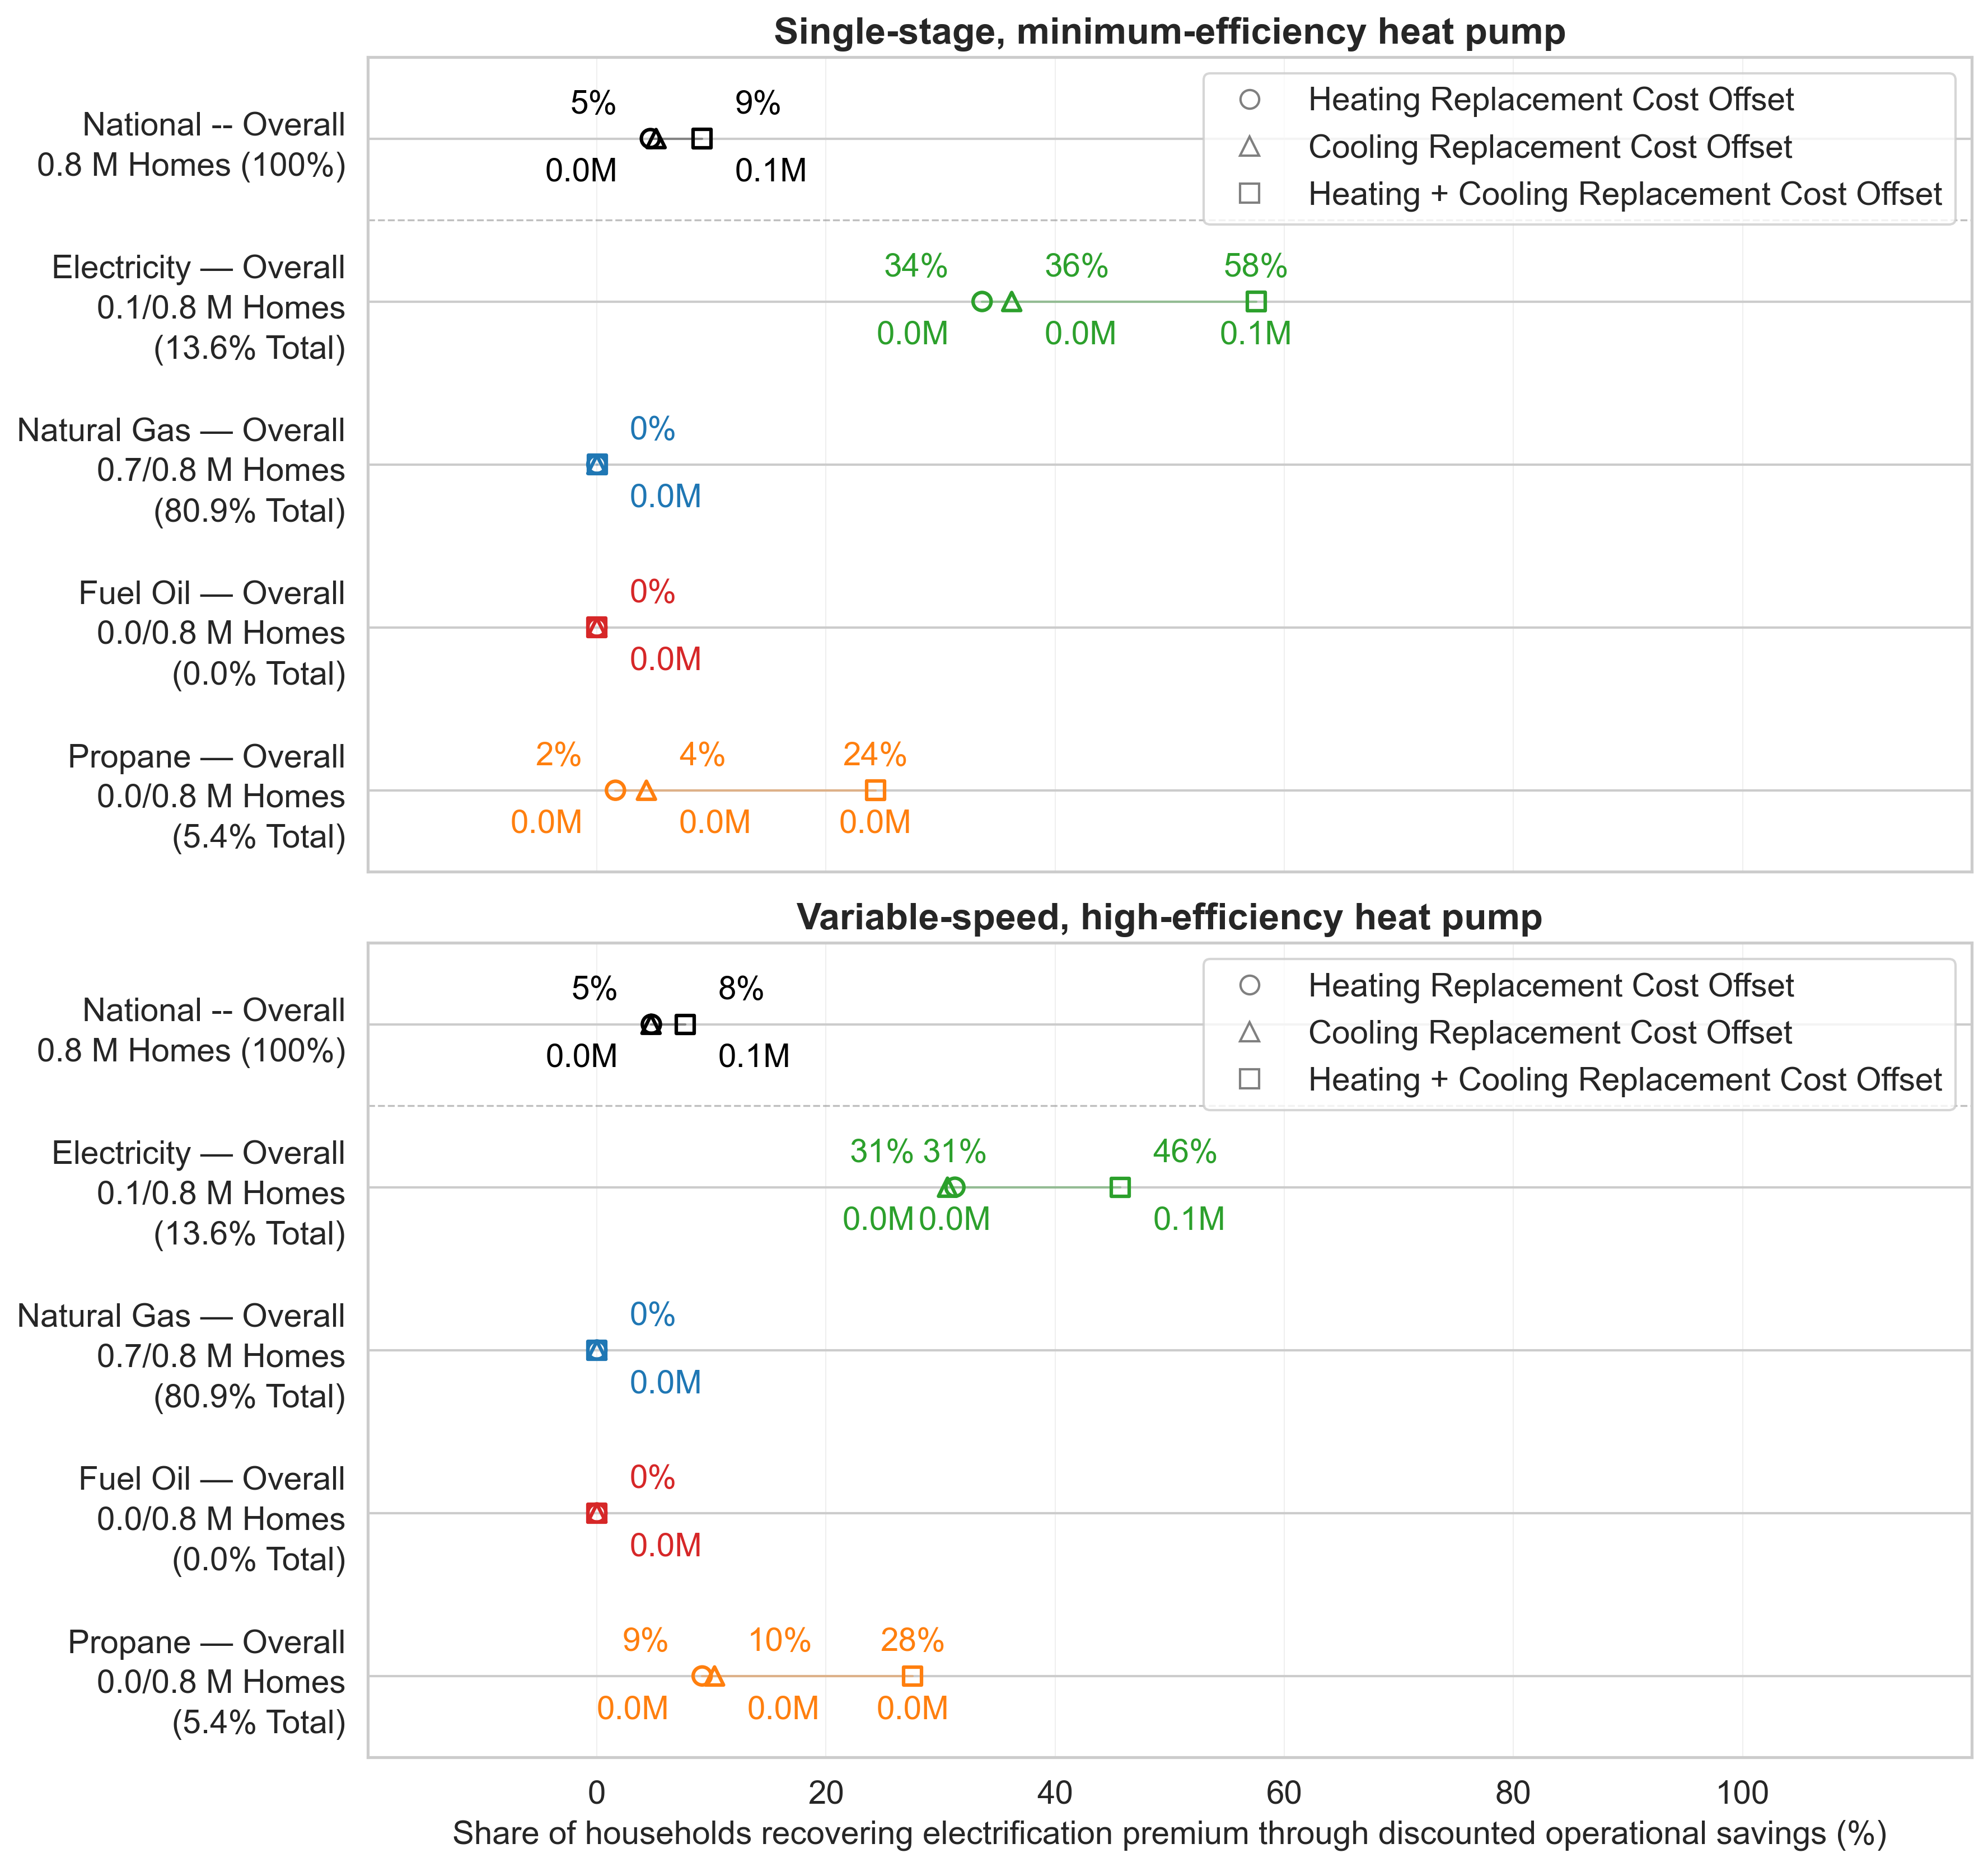

In [10]:
# =============================================================================
# ECONOMIC ADOPTION (Dotplot) -- Replacement Cost Offset Sensitivity
# =============================================================================

if not HEATING_MEASURE_PACKAGES:
    print("No active heating measure packages -- skipping economic adoption dotplot.")
else:
    # Set Seaborn theme for consistent styling across all dotplot figures. 
    sns.set_theme(font='sans-serif', style='whitegrid')

    plot_econ_adoption_dotplot_figure(
        HEATING_MEASURE_PACKAGES, DATAFRAMES_BY_MP, discount_rate, _COST,
        HEATING_MP_SUBTITLES,
        build_df_kwargs=dict(rebate_vintage='unsub'),
        custom_tier_markers=REPLACEMENT_CREDIT_MARKERS,
        legend_handles=build_replacement_credit_legend_handles(fill_markers=False),
        summary_header='economic adoption summary (National, unsubsidized)',
        annotation_x_offset_pts=14.0,
        annotation_y_offset_pts=8.0,
        save_figure=SAVE_FIGURES,
        output_dir=PROJECT_ROOT,
        output_filename=f'figure6_econ_adoption_dotplot_{location_id}',
        figure_dpi=FIGURE_DPI,
    )


### Sensitivity of Heat Pump Adoption to Rebate Policy Scenario

-- Scenario: 2025 Reference Case (mp3) --
-- Scenario: 2025 Reference Case (mp3) --
--- MP3 adoption by rebate policy scenario (heatingLCC_coolingLCC) ---
  Unsubsidized: 9.2%
  2024 Rebate: 28.3%
  2026 Rebate w/o fuel switching: 10.9%

-- Scenario: 2025 Reference Case (mp4) --
-- Scenario: 2025 Reference Case (mp4) --
--- MP4 adoption by rebate policy scenario (heatingLCC_coolingLCC) ---
  Unsubsidized: 7.7%
  2024 Rebate: 15.8%
  2026 Rebate w/o fuel switching: 11.7%

[OK] Saved econ_adoption_dotplot_rebate_policy_scenario_heatingLCC_coolingLCC.png / .pdf to c:\Users\tamar\Documents\Research\cmu-tare-model\figures


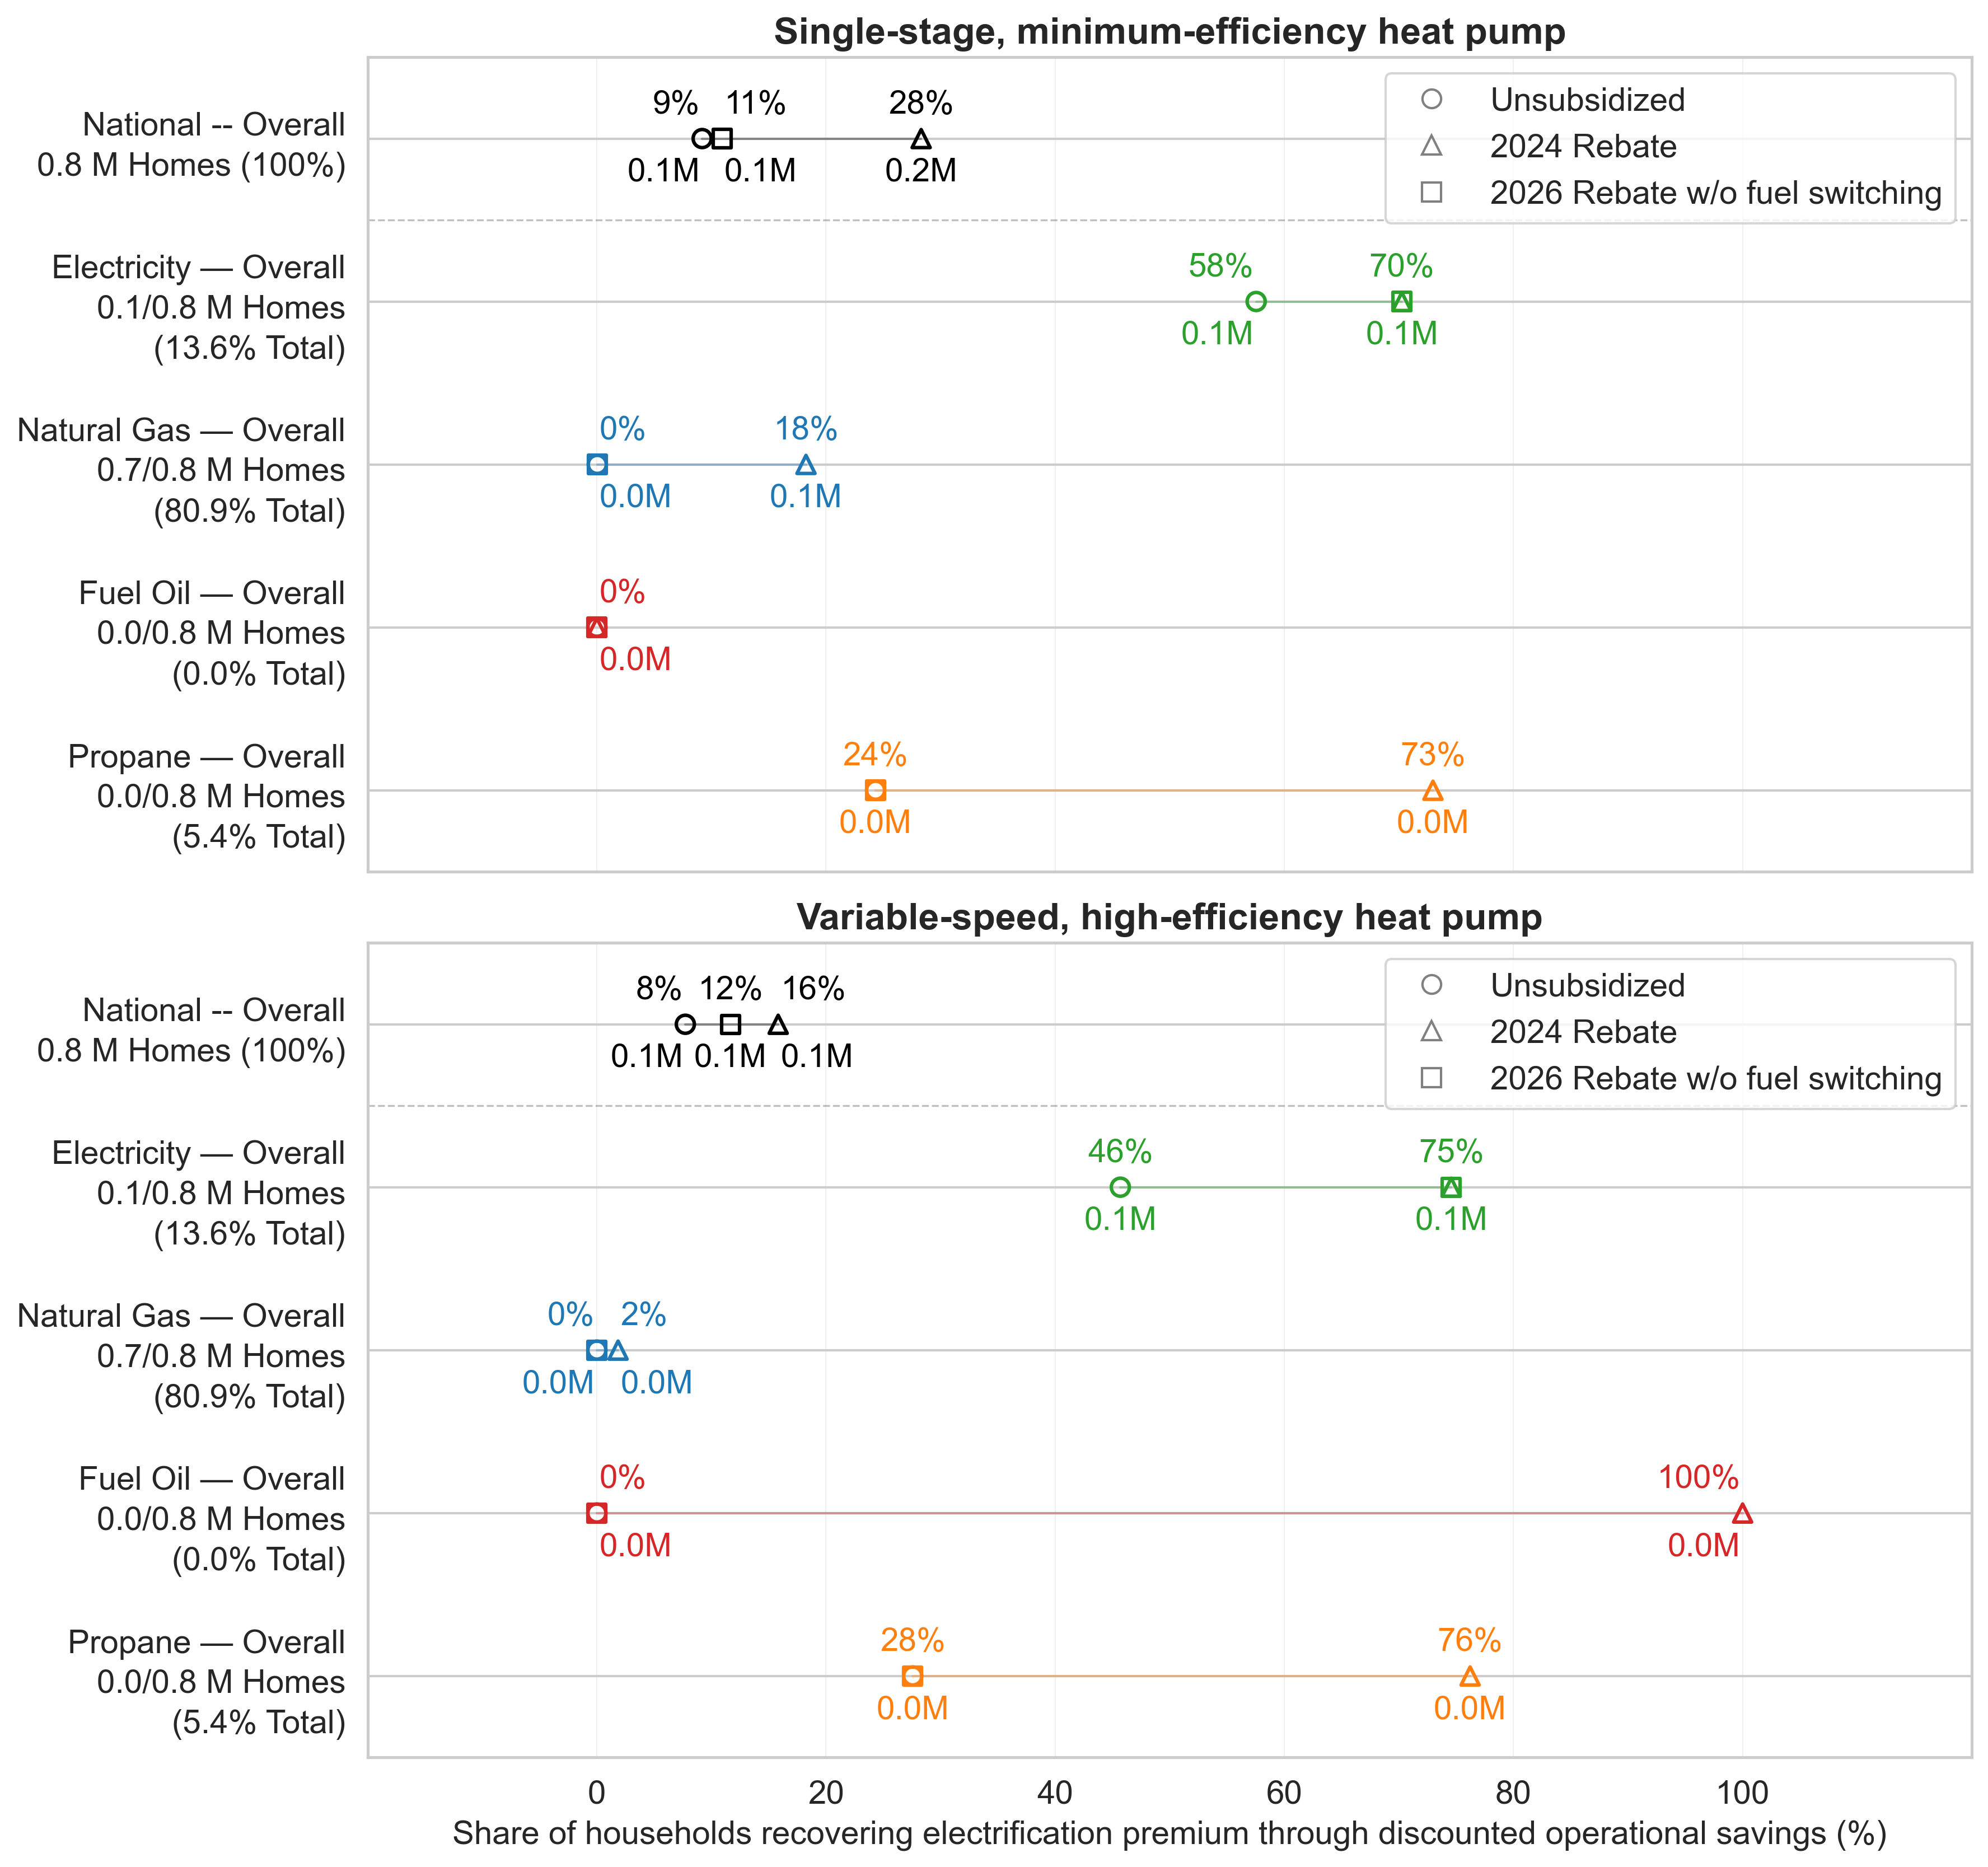

In [11]:
# =============================================================================
# ECONOMIC ADOPTION (Dotplot) -- Rebate Policy Scenario Sensitivity
# =============================================================================
# Hold this replacement-credit scenario fixed; the three markers vary the rebate
# policy scenario. Switch to 'heatingLCC_coolingSavings' for the heating-only view.
_FIXED_CREDIT = 'heatingLCC_coolingLCC'

if not HEATING_MEASURE_PACKAGES:
    print("No active heating measure packages -- skipping rebate-policy dotplot.")
else:
    # Set Seaborn theme for consistent styling across all dotplot figures. 
    sns.set_theme(font='sans-serif', style='whitegrid')

    plot_econ_adoption_dotplot_figure(
        HEATING_MEASURE_PACKAGES, DATAFRAMES_BY_MP, discount_rate, _COST,
        HEATING_MP_SUBTITLES,
        build_df_kwargs=dict(
            shape_by='rebate_policy_scenario',
            fixed_replacement_credit_scenario=_FIXED_CREDIT,
        ),
        custom_tier_markers=REBATE_POLICY_SCENARIO_MARKERS,
        legend_handles=build_rebate_policy_scenario_legend_handles(fill_markers=False),
        summary_header=f'adoption by rebate policy scenario ({_FIXED_CREDIT})',
        annotation_x_offset_pts=1.0,
        annotation_y_offset_pts=8.0,
        save_figure=SAVE_FIGURES,
        output_dir=PROJECT_ROOT,
        output_filename=f'econ_adoption_dotplot_rebate_policy_scenario_{_FIXED_CREDIT}',
        figure_dpi=FIGURE_DPI,
    )


## County Level Maps

In [12]:
# =============================================================================
# Retrofit impact on electricity demand and operating cost (county choropleths)
# =============================================================================
from cmu_tare_model.adoption_kpis.data_loading import load_euss_upgrade, mp_to_upgrade
from cmu_tare_model.adoption_kpis.demand import compute_scenario_demand, aggregate_demand

# Step 1 -- load EUSS upgrade energy for each measure package.
upgrade_data = {}
for mp in selected_mps:
    upgrade_name = mp_to_upgrade(mp)
    print(f"Loading MP{mp} ({upgrade_name})...")
    upgrade_data[mp] = load_euss_upgrade(upgrade_name)
    print(f"  MP{mp}: {len(upgrade_data[mp]):,} applicable rdu")

# Step 2 -- operating-cost % change (county median of per-home percent change).
print(f"\n{'='*60}")
print("OPERATING COST % CHANGE -- average annual, all fuels, 100% adoption")
print(f"{'='*60}")

bill_savings_results = {}
for mp in selected_mps:
    print(f"\n===== {HEATING_MP_SUBTITLES.get(mp, f'MP{mp}')} =====")
    df_tare = DATAFRAMES_BY_MP[mp][discount_rate]
    scenario_prefix = define_scenario_params(mp, _POLICY)[0]
    pct_col = f"{scenario_prefix}heating_avg_annual_fuel_cost_pct_change"
    if pct_col not in df_tare.columns:
        raise KeyError(
            f"Average-annual operating-cost column '{pct_col}' not found for "
            f"MP{mp}. Re-run the fuel-cost pipeline "
            "(calculate_lifetime_fuel_costs) so the average-annual columns are "
            "materialized, then reload DATAFRAMES_BY_MP."
        )
    # County median of the materialized per-home percent change, study sample
    # only, so counties with no sample homes are left out instead of blank.
    df_sample = df_tare.loc[df_tare['include_sample']]
    df_county = (
        pd.DataFrame({
            'county': df_sample['county'],
            'operating_cost_pct_change': df_sample[pct_col],
        })
        .groupby('county')['operating_cost_pct_change']
        .median()
        .reset_index()
    )
    print(
        f"  Per-home valid records: {df_sample[pct_col].notna().sum():,} | "
        f"Counties: {len(df_county):,}"
    )
    bill_savings_results[mp] = df_county

# Step 3 -- ANNUAL electricity demand change in 2025 (county-level GWh and percent). Both
# elec_change_gwh and pct_elec_demand_change come straight from aggregate_demand.
from cmu_tare_model.adoption_kpis.demand import build_demand_breakdown

print(f"\n{'='*60}")
print("DEMAND CHANGE -- all fuels, 100% adoption")
print(f"{'='*60}")

demand_results = {}
demand_frames = {}  # each package's per-home frame, kept for the breakdown below
for mp in selected_mps:
    print(f"\n===== {HEATING_MP_SUBTITLES.get(mp, f'MP{mp}')} =====")

    demand_frames[mp] = compute_scenario_demand(
        df_baseline=df_baseline, df_upgrade=upgrade_data[mp],
        sample_bldg_ids=TARE_SAMPLE_IDS['all'], fuel_filter=None, verbose=False,
    )

    demand_results[mp] = aggregate_demand(
        df_demand=demand_frames[mp], geo_level='county',
    )

# Side-by-side breakdown, GWh at 100% adoption (the last row is a percent).
print(f"\n{'='*60}")
print("DEMAND BREAKDOWN -- GWh at 100% adoption, study sample")
print(f"{'='*60}")
df_demand_breakdown = pd.DataFrame({
    f"MP{mp}": build_demand_breakdown(demand_frames[mp]) for mp in selected_mps
})
print(df_demand_breakdown.to_string(float_format='{:,.3f}'.format))


Loading MP3 (upgrade03)...
        stage  rdu_count  weighted_count  Electricity_pct  Electricity ASHP_pct  Fuel Oil_pct  Natural Gas_pct  Propane_pct
         load     548916    1.329096e+08        28.971464             11.159449      4.686692        47.710761     4.632221
applicability     548260    1.327507e+08        28.886477             11.172801      4.692299        47.767847     4.637763
    occupancy     482050    1.167193e+08        28.346230             10.862359      4.649103        49.069184     4.375480
 housing_type     396122    9.591342e+07        24.523000             10.130970      5.007548        52.241481     5.206729
exclude_AK_HI     396122    9.591342e+07        24.523000             10.130970      5.007548        52.241481     5.206729
  MP3: 396,122 applicable rdu
Loading MP4 (upgrade04)...
        stage  rdu_count  weighted_count  Electricity_pct  Electricity ASHP_pct  Fuel Oil_pct  Natural Gas_pct  Propane_pct
         load     548916    1.329096e+08        

In [13]:
# =============================================================================
# Operating cost percent change (county-level) -- separate function call
# =============================================================================
if gdf_counties_raw is not None:
    # ---- Operating cost percent change (county-level) ----
    plot_national_county_change_map(
        gdf_counties_raw, bill_savings_results,
        column='operating_cost_pct_change',
        cbar_label='Post-retrofit change in average annual operating cost, relative to baseline equipment (%)',
        cmap='RdBu_r',
        title_template=HEATING_MP_SUBTITLES,
        selected_mps=selected_mps,
        positive_direction='HP saves money (< 0)',
        norm_label='Operating cost %',
        norm_unit='%',
        save_figure=SAVE_FIGURES,
        output_filename='county_bill_pct_change_combined.png',
    )
    

In [14]:
# =============================================================================
# Electricity demand change (GWh, county-level) -- separate function call
# =============================================================================
if gdf_counties_raw is not None:
    # ---- Electricity demand change (GWh, county-level) ----
    plot_national_county_change_map(
        gdf_counties_raw, demand_results,
        column='elec_change_gwh',
        cbar_label='Post-retrofit change in 2025 annual electricity demand, relative to baseline (GWh)',
        cmap='coolwarm',
        title_template=HEATING_MP_SUBTITLES,
        selected_mps=selected_mps,
    positive_direction='increase',
    norm_label='Demand GWh',
    norm_unit=' GWh',
    save_figure=SAVE_FIGURES,
    output_filename='county_elec_demand_gwh_combined.png',
)


In [15]:
# =============================================================================
# Electricity demand percent change (county-level) -- separate function call
# =============================================================================
if gdf_counties_raw is not None:
    # ---- Electricity demand percent change (county-level) ----
    plot_national_county_change_map(
        gdf_counties_raw, demand_results,
        column='pct_elec_demand_change',
        cbar_label='Post-retrofit change in 2025 annual electricity demand, relative to baseline (%)',
        cmap='coolwarm',
        title_template=HEATING_MP_SUBTITLES,
        selected_mps=selected_mps,
        positive_direction='increase',
        norm_label='Demand %',
        norm_unit='%',
        save_figure=SAVE_FIGURES,
        output_filename='county_elec_demand_pct_combined.png',
    )


In [16]:
# =============================================================================
# Tepper CSV exports -- household and county files for each export scope
# =============================================================================
# Reuses objects already in memory from this notebook run:
#   DATAFRAMES_BY_MP[mp]['fixed_base']  -- household frame (per MP)
#   econ_adoption_rate_results[mp]      -- county adoption table
#   bill_savings_results[mp]            -- county operating-cost table
#   demand_results[mp]                  -- county demand table
# and the run identifiers output_folder_path / location_id / model_run_date_time.
#
# The household files hold study-sample rows only; export_tepper_household
# applies that filter itself. Each scope gets a main household file, a detailed
# copy with each year's energy use split by fuel, and a county file.

# Set False to skip the export. The national scope writes about 1.4 GB of
# household files per measure package.
EXPORT_TEPPER_FILES = True

if EXPORT_TEPPER_FILES:
    from cmu_tare_model.utils.export_model_run_results import export_model_run_output
    from cmu_tare_model.utils.export_tepper_csv import (
        export_source_data_copies,
        filter_to_export_scope,
    )

    # Step 1 -- the adoption and demand tables must describe the same homes.
    # Both count the study sample, so each county's home count has to agree to
    # within one home's weight (read from the data, not hardcoded). A county
    # missing from either table has a blank gap, which fails the test too.
    one_home_weight = df_baseline["weight"].median()
    for mp in selected_mps:
        df_home_counts = econ_adoption_rate_results[mp][
            ["county", "home_count"]
        ].merge(
            demand_results[mp][["county", "home_count"]],
            on="county", how="outer", suffixes=("_adoption", "_demand"),
        )
        home_count_gap = (
            df_home_counts["home_count_adoption"]
            - df_home_counts["home_count_demand"]
        ).abs()
        n_counties_disagree = int((~(home_count_gap <= one_home_weight)).sum())
        if n_counties_disagree:
            raise ValueError(
                f"MP{mp}: home_count differs between the adoption and demand "
                f"tables in {n_counties_disagree:,} counties, so the two tables "
                "do not describe the same homes."
            )
        print(
            f"[OK] MP{mp}: home_count agrees in all "
            f"{len(df_home_counts):,} counties."
        )

    # Step 2 -- export scopes. Filtering happens here, not at model run scope,
    # so one national run can produce a national set of files plus any number
    # of state or county sets.
    #
    #   label   -- goes in the file names
    #   column  -- 'state' (two-letter code) or 'county' (Census GISJOIN code).
    #              None keeps every row.
    #   value   -- what that column must equal
    #
    # To add a scope, copy a line. A whole state is
    # {"label": "PA", "column": "state", "value": "PA"}; another county is its
    # Census GISJOIN code, e.g. "G4200030" for Allegheny County, PA.
    TEPPER_EXPORT_SCOPES = [
        {"label": location_id, "column": None, "value": None},
        {"label": "Allegheny", "column": "county", "value": "G4200030"},
    ]

    for mp in selected_mps:
        # Per-year consumption for this measure package. The file also holds
        # the per-year fuel costs; the export takes only the consumption columns.
        df_annual_consumption = load_model_run_output(
            results_category='fuel_costs_ref2025',
            menu_mp=mp,
            output_folder_path=output_folder_path,
            location_id=location_id,
            results_export_formatted_date=model_run_date_time,
        )

        df_household = DATAFRAMES_BY_MP[mp]['fixed_base']
        county_tables_full = {
            'adoption': econ_adoption_rate_results[mp],
            'bill_savings': bill_savings_results[mp],
            'demand': demand_results[mp],
        }

        for scope in TEPPER_EXPORT_SCOPES:
            scope_label = scope["label"]
            scope_column = scope["column"]
            scope_value = scope["value"]

            # Skip a scope that this run does not cover, rather than failing.
            # A single-state run will not contain most counties.
            if scope_column is not None:
                if not (df_household[scope_column] == scope_value).any():
                    print(
                        f"[INFO] MP{mp}: no rdu match {scope_column} = "
                        f"{scope_value!r}; skipping the {scope_label} files."
                    )
                    continue

            df_scope = filter_to_export_scope(
                df_household, scope_column, scope_value)

            # Household CSVs: the main file and the detailed copy.
            export_model_run_output(
                df_results_export=df_scope,
                results_category='tepper_household',
                menu_mp=mp,
                output_folder_path=output_folder_path,
                location_id=scope_label,
                results_export_formatted_date=model_run_date_time,
                df_annual_consumption=df_annual_consumption,
            )

            # County CSV: the three county tables, limited to this scope's
            # counties. The bill-savings table has no 'state' column, so the
            # scope is applied through the county codes of the household rows.
            scope_counties = df_scope['county'].unique()
            county_tables_scope = {}
            for table_name, df_county_table in county_tables_full.items():
                county_tables_scope[table_name] = df_county_table[
                    df_county_table['county'].isin(scope_counties)]

            export_model_run_output(
                df_results_export=None,  # not used by the county export
                results_category='tepper_county',
                menu_mp=mp,
                output_folder_path=output_folder_path,
                location_id=scope_label,
                results_export_formatted_date=model_run_date_time,
                county_tables=county_tables_scope,
            )

    print(
        "\nTepper exports written to: "
        f"{os.path.join(output_folder_path, 'tepper_export')}"
    )

    # The three input files the fuel-price lookup uses, copied unchanged, so a
    # reader can redo the lookup themselves.
    export_source_data_copies(output_folder_path)


[OK] MP3: home_count agrees in all 62 counties.
[OK] MP4: home_count agrees in all 62 counties.
Loading mp3_fuel_costs_ref2025_CO_2026-10-19_13-41.csv in chunks of 50,000 rows...
  Successfully combined 1 chunks into DataFrame with shape (6783, 291)
Loaded: mp3_fuel_costs_ref2025_CO_2026-10-19_13-41.csv
Shape: (6783, 291)

---------------------------------------------------------------------------------------------------------
-- Scenario: 2025 Reference Case (mp3) --
-- Scenario: 2025 Reference Case (mp3) --
-- Scenario: 2025 Reference Case (mp3) --
-- Scenario: 2025 Reference Case (mp3) --
-- Scenario: 2025 Reference Case (mp3) --
[OK] Tepper household export written
     MP3 | 3,406 rows x 167 columns (+ bldg_id index)
     Path: c:\Users\tamar\Documents\Research\cmu-tare-model\cmu_tare_model\output_results\tepper_export\tepper_household_mp3_CO_2026-10-19_13-41.csv
[OK] Tepper household export written
     MP3 | 3,406 rows x 317 columns (+ bldg_id index)
     Path: c:\Users\tamar\Do

NG Furnace baseline population: 2,572 | ASHP upgrade population: MP3 3,406 | MP4 3,406


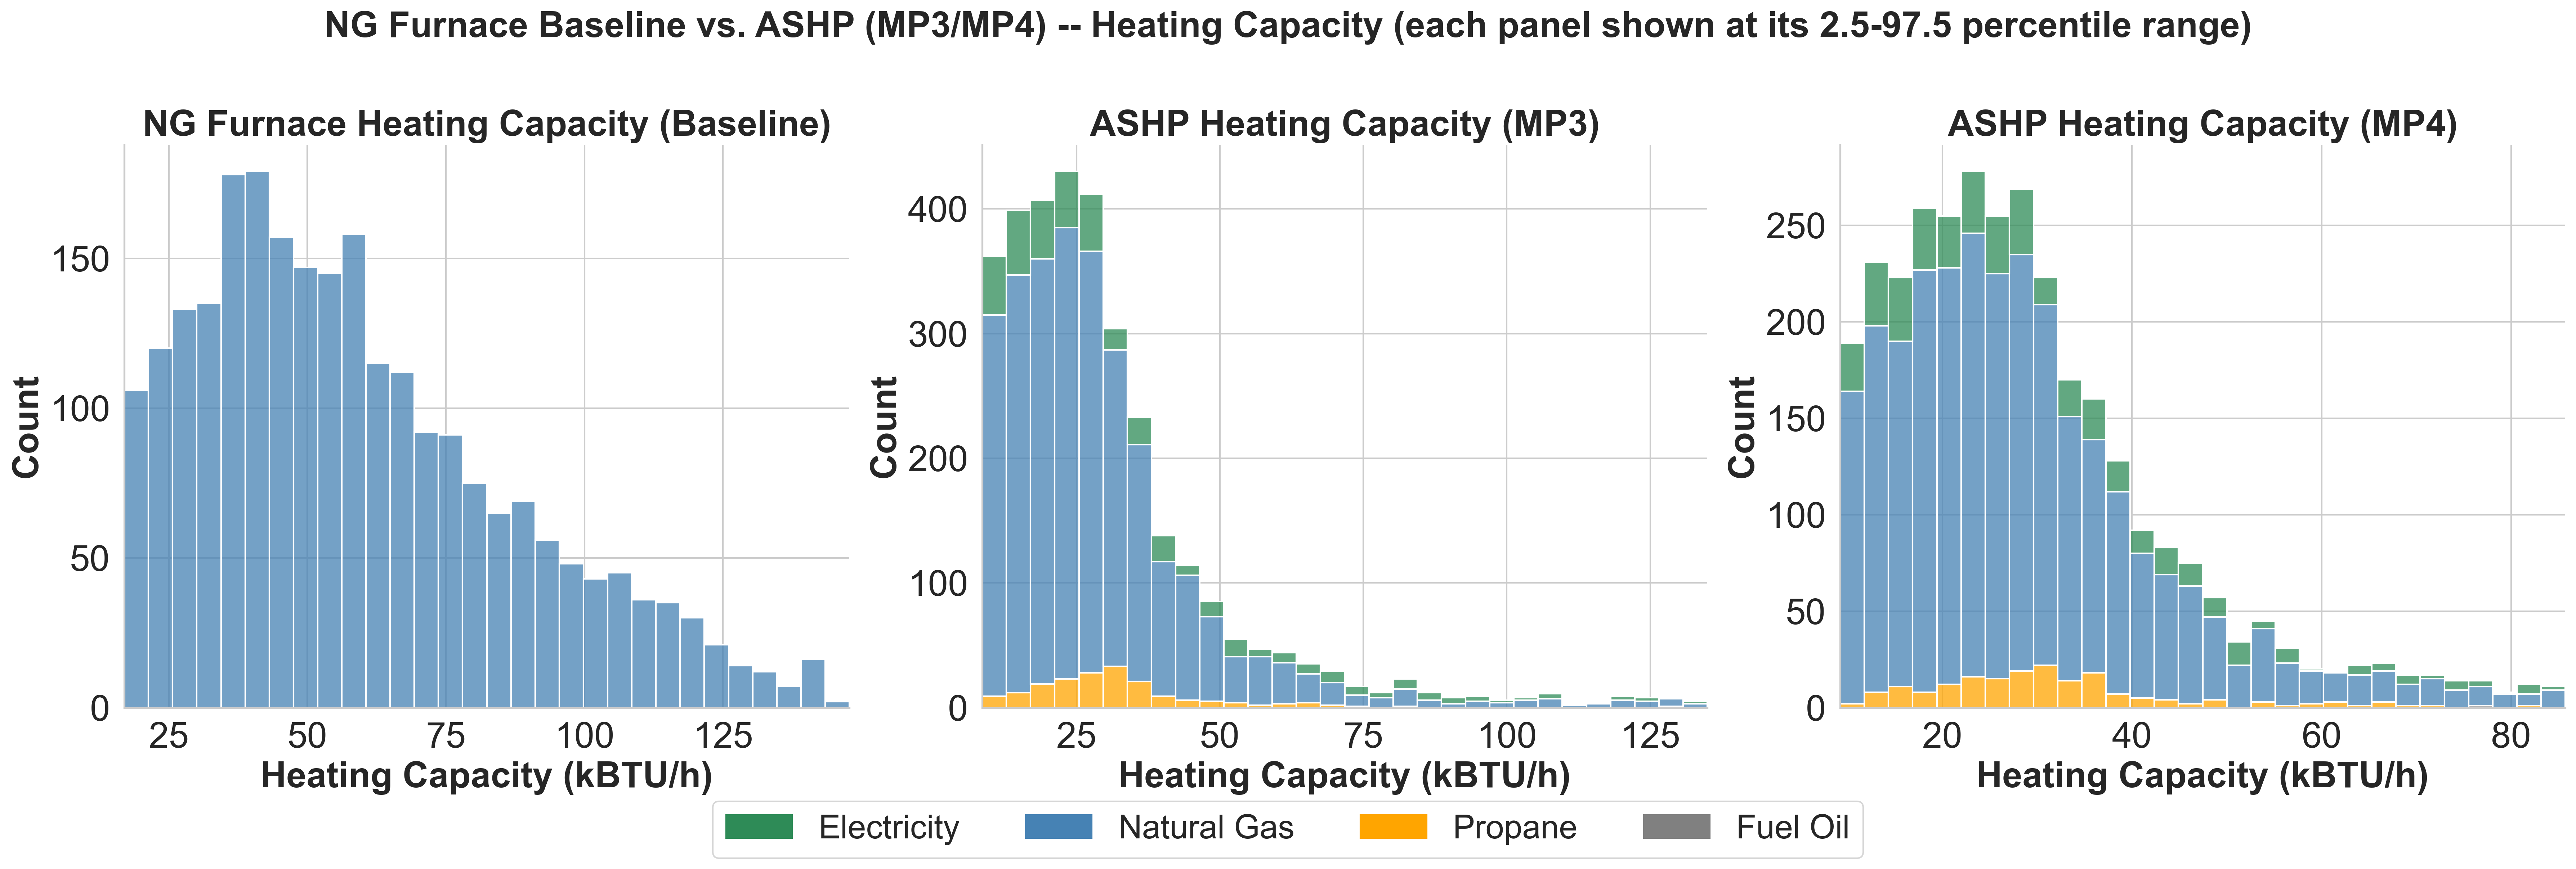

In [17]:
# =============================================================================
# Furnace vs ASHP -- Metric Comparison (Heating Capacity)
# =============================================================================
if RUN_MP3_MP4_COST_VALIDATION:
    fig_capacity = build_furnace_ashp_metric_comparison_figure(
        df_mp3_ccv, df_mp4_ccv,
        baseline_col='base_size_heating_system_primary_k_btu_h',
        mp3_col='size_heating_system_primary_k_btu_h',
        mp4_col='size_heating_system_primary_k_btu_h',
        x_label='Heating Capacity (kBTU/h)',
        metric_label='Heating Capacity',
    )
    plt.show()


NG Furnace baseline population: 2,572 | ASHP upgrade population: MP3 3,406 | MP4 3,406


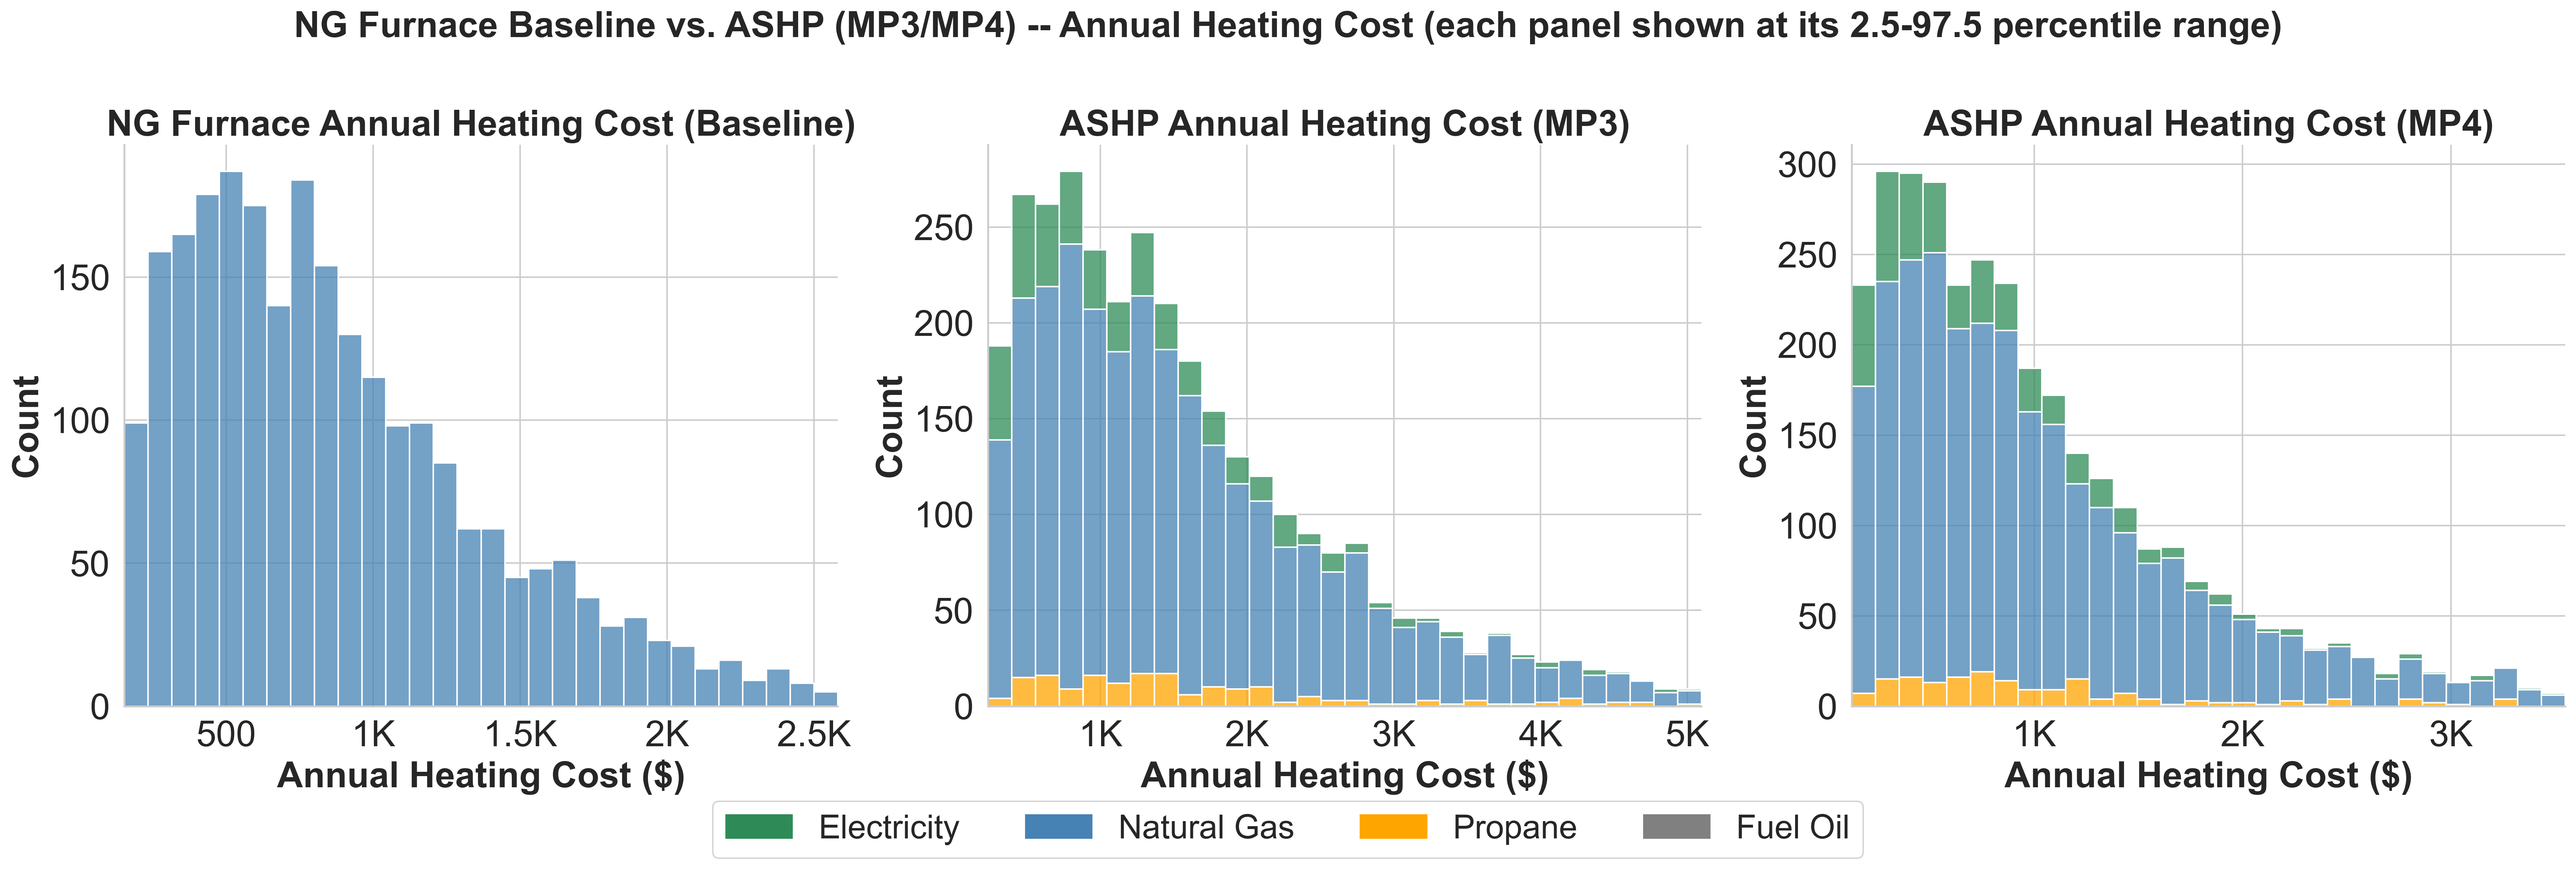

In [18]:
# =============================================================================
# Furnace vs ASHP -- Metric Comparison (Annual Heating Cost)
# =============================================================================
if RUN_MP3_MP4_COST_VALIDATION:
    fig_cost = build_furnace_ashp_metric_comparison_figure(
        df_mp3_ccv, df_mp4_ccv,
        baseline_col='baseline_heating_avg_annual_fuel_cost',
        mp3_col='ref2025_mp3_heating_avg_annual_fuel_cost',
        mp4_col='ref2025_mp4_heating_avg_annual_fuel_cost',
        x_label='Annual Heating Cost ($)',
        metric_label='Annual Heating Cost',
    )
    plt.show()


ASHP upgrade population: MP3 3,406 rdu | MP4 3,406 rdu

Heating consumption summary (kWh, all baseline fuels):
                                        N (rdu)   Mean  Min (P2.5)   P25   P50    P75  Max (P97.5)
ASHP Primary Heating Consumption (MP3)     3406  4,634         987 2,519 3,996  5,938       12,159
ASHP Total Heating Consumption (MP3)       3406 10,137       1,438 4,592 8,061 13,165       31,146
ASHP Primary Heating Consumption (MP4)     3406  3,641         615 1,876 3,086  4,734        9,841
ASHP Total Heating Consumption (MP4)       3406  6,605         764 2,692 4,994  8,496       21,682


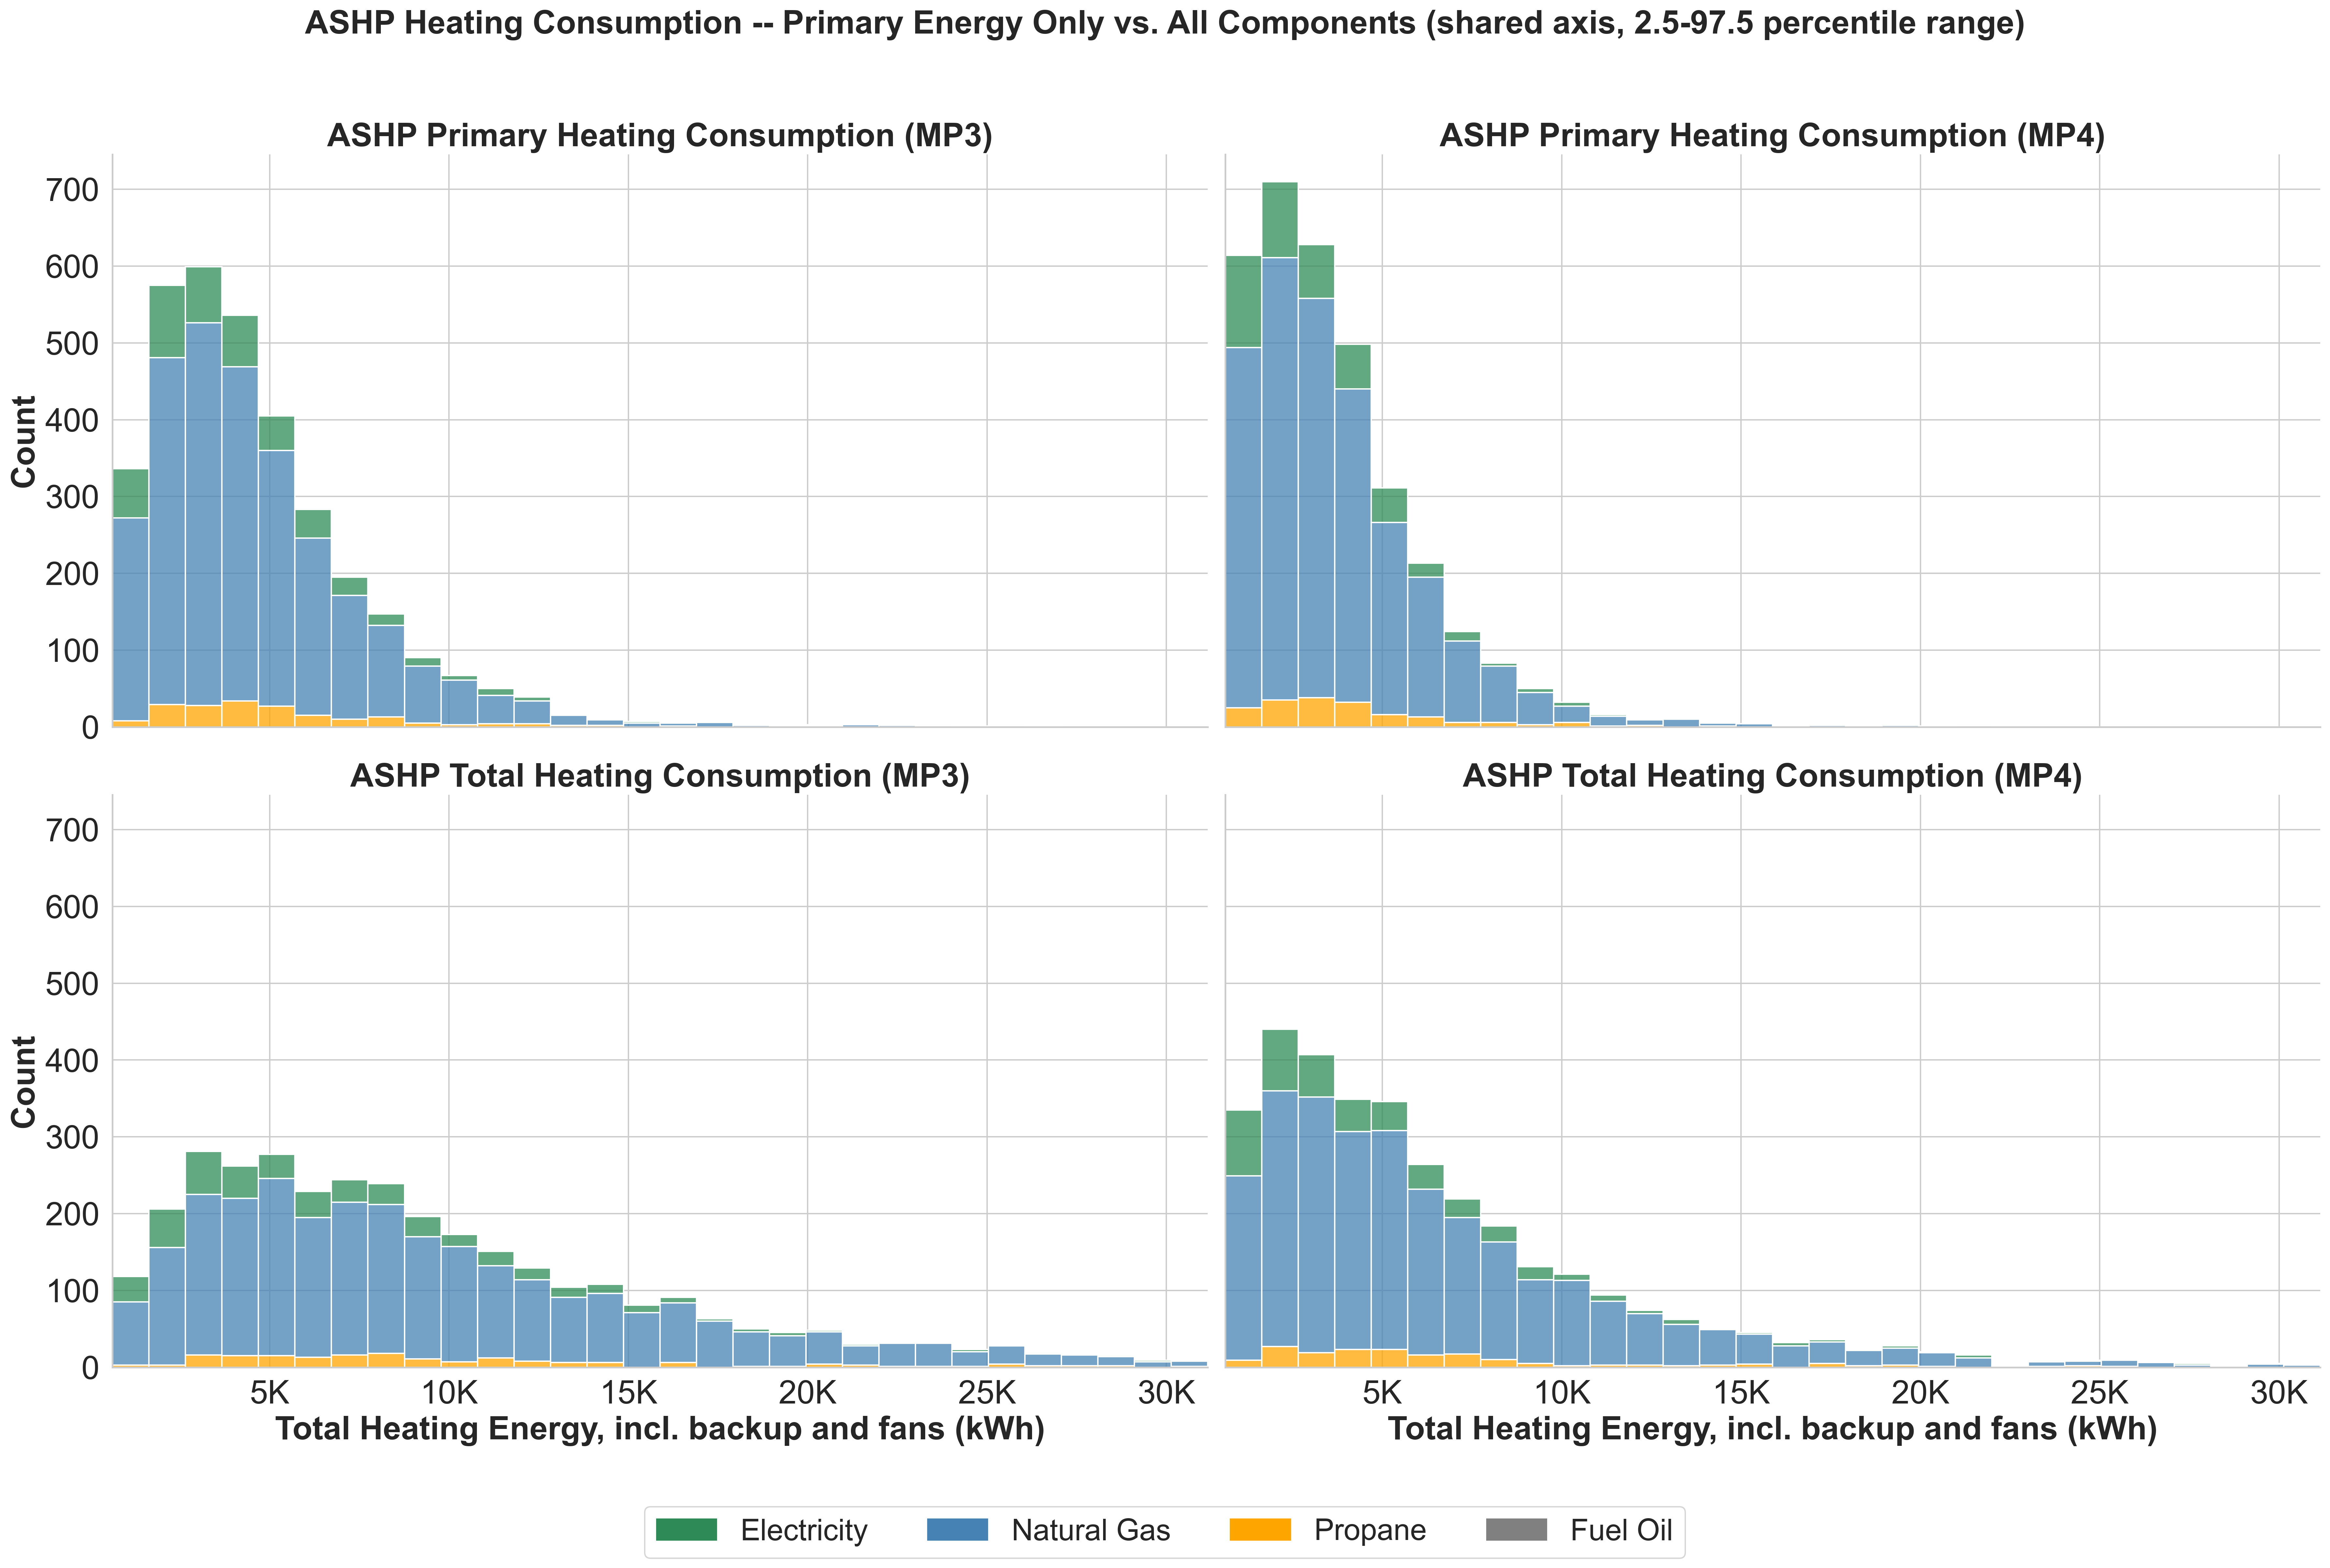

In [19]:
# =============================================================================
# Furnace vs ASHP -- Primary vs Total Consumption (kWh) -- separate function call
# =============================================================================
if RUN_MP3_MP4_COST_VALIDATION:
    fig_primary_vs_total = build_ashp_primary_vs_total_consumption_figure(
        df_mp3=df_mp3_ccv,
        df_mp4=df_mp4_ccv,
        sharex=True,
        sharey=True,
    )
    plt.show()


# GRID IMPACT ANALYSIS

In [20]:
# =============================================================================
# GRID IMPACT -- build adopter building IDs by measure package and county
# =============================================================================
# Produces adopter_ids_by_mp, consumed by the BSQ timeseries and county-profile
# cells below. Two adopter sets per county:
#   all_filtered -- every study-sample home in the county (100% adoption bound)
#   constrained  -- buildings that are economic adopters (econ_adopter == 1.0),
#                   i.e. the heat pump pays for itself at NPV >= 0. This matches
#                   the economic-adoption definition used throughout the
#                   notebook; it is NOT the deprecated Tier 1+2 tiered split.
#
# The constrained set uses BASE_CASE_NPV_CASE (the study base case, defined once
# in column_names.py: 'heatingLCC_coolingLCC_unsub' -- unsubsidized, both the
# heating and cooling replacement costs credited in the NPV). npv_case is passed
# by keyword so the adopter column can never silently fall back to
# find_adoption_column's default (a positional call previously routed this
# figure to the wrong case).
from cmu_tare_model.utils.column_names import BASE_CASE_NPV_CASE

adopter_ids_by_mp = {}
adoption_col_by_mp = {}

for mp in selected_mps:
    df_tare = DATAFRAMES_BY_MP[mp][discount_rate]

    # Derive the economic-adopter column via the helper -- no hardcoded prefix.
    # The cost token does not change the column name (it was dropped from output
    # names in the July 2026 refactor), so any key in REMDB_COST_SCENARIO_KEYS
    # resolves the same column; the loop just takes the first one that succeeds.
    # All arguments are passed by keyword so a positional slip cannot silently
    # change the case.
    adoption_col = None
    for cost_scenario in REMDB_COST_SCENARIO_KEYS:
        try:
            adoption_col = find_adoption_column(
                df=df_tare,
                mp=mp,
                cost_scenario=cost_scenario,
                discount_rate_key=discount_rate,
                npv_case=BASE_CASE_NPV_CASE,
            )
            break
        except KeyError:
            continue
    if adoption_col is None:
        # Re-raise with full diagnostics using the first cost scenario key.
        adoption_col = find_adoption_column(
            df=df_tare,
            mp=mp,
            cost_scenario=REMDB_COST_SCENARIO_KEYS[0],
            discount_rate_key=discount_rate,
            npv_case=BASE_CASE_NPV_CASE,
        )
    adoption_col_by_mp[mp] = adoption_col

    # Split each county's sample homes into the 100% set (every sample home)
    # and the economic-adopter set. A NaN adopter value is not 1.0, so it is
    # left out of constrained.
    is_adopter = df_tare[adoption_col] == 1.0

    adopter_ids_by_mp[mp] = {}
    for fips, county_sample_ids in TARE_SAMPLE_IDS['by_county'].items():
        county_is_adopter = is_adopter.loc[county_sample_ids].to_numpy()
        adopter_ids_by_mp[mp][fips] = {
            "all_filtered": list(county_sample_ids),
            "constrained": [
                bldg_id
                for bldg_id, is_econ_adopter in zip(county_sample_ids, county_is_adopter)
                if is_econ_adopter
            ],
        }

    # Every adopter must be a sample home; a mismatch means the frames and
    # the saved sample come from different runs.
    n_adopters_in_sample = sum(
        len(county_ids["constrained"]) for county_ids in adopter_ids_by_mp[mp].values())
    n_adopters_total = int(is_adopter.sum())
    if n_adopters_in_sample != n_adopters_total:
        raise ValueError(f"MP{mp}: {n_adopters_total:,} adopters but "
                         f"{n_adopters_in_sample:,} in the sample")

    n_counties = len(adopter_ids_by_mp[mp])
    n_all = sum(len(county_ids["all_filtered"]) for county_ids in adopter_ids_by_mp[mp].values())
    n_con = sum(len(county_ids["constrained"]) for county_ids in adopter_ids_by_mp[mp].values())
    print(f"[OK] MP{mp}: adoption column {adoption_col}")
    print(f"     Counties: {n_counties:,} | all_filtered: {n_all:,} | "
          f"constrained (NPV>=0): {n_con:,}")

print(f"\n[OK] adopter_ids_by_mp built for MPs: {list(adopter_ids_by_mp.keys())}")


[OK] MP3: adoption column ref2025_mp3_heatingLCC_coolingLCC_unsub_econ_adopter_fixed_base
     Counties: 62 | all_filtered: 3,406 | constrained (NPV>=0): 313
[OK] MP4: adoption column ref2025_mp4_heatingLCC_coolingLCC_unsub_econ_adopter_fixed_base
     Counties: 62 | all_filtered: 3,406 | constrained (NPV>=0): 263

[OK] adopter_ids_by_mp built for MPs: [3, 4]


### Grid Impact Analysis -- AWS troubleshooting (optional)

In [21]:
# ============================================================================
# BSQ / AWS troubleshooting diagnostic (optional)
# ----------------------------------------------------------------------------
# Set RUN_BSQ_DIAGNOSTIC = True to check the AWS setup before running the
# grid-impact cells below. It runs seven checks -- buildstock_query install,
# AWS credentials, the Athena workgroup, the query-result bucket, the Glue
# tables, BuildStockQuery initialization, and one real end-to-end query -- and
# prints what to fix for whichever one fails first.
#
# Leave it False for normal runs. It issues two small Athena queries, so it
# takes a few seconds and a fraction of a cent.
#
# The same checks from a terminal:
#     python -m cmu_tare_model.grid_impact.diagnose_bsq_aws
#
# What each check means: cmu_tare_model/docs/BSQ_AWS_SETUP.md
# ============================================================================
RUN_BSQ_DIAGNOSTIC = False

if RUN_BSQ_DIAGNOSTIC:
    from cmu_tare_model.grid_impact.diagnose_bsq_aws import run_diagnostic

    bsq_diagnostic_exit_code = run_diagnostic()

    if bsq_diagnostic_exit_code != 0:
        print(
            "\n[ACTION NEEDED] A check above did not pass. The grid-impact "
            "cells below will not run until it is resolved.\n"
            "                See cmu_tare_model/docs/BSQ_AWS_SETUP.md, Part 2."
        )
else:
    print(
        "[SKIP] BSQ / AWS diagnostic not run. "
        "Set RUN_BSQ_DIAGNOSTIC = True above to troubleshoot the AWS setup."
    )


[SKIP] BSQ / AWS diagnostic not run. Set RUN_BSQ_DIAGNOSTIC = True above to troubleshoot the AWS setup.


### Grid Impact Analysis using BuildStockQuery and AWS-hosted ResStock data

In [22]:
# TODO (grid impact, 2025.1): the grid impact analysis (this cell to the peak
# load figures) works on ResStock 2022.1.1 only for now. It will be updated
# for the dual-fuel analysis (2025.1).

# custom_weighting picks which of the two weighting paths this section runs.
# False keeps today's behavior (one county, BSQ's own uniform weight); 
# True switches to custom tax-parcel weights. See
# compute_county_scenario_profile for how each path is actually applied.
CUSTOM_WEIGHTING = True


if GRID_IMPACT_ANALYSIS:
    from cmu_tare_model.grid_impact.peak_load_functions import (
        print_heating_fuel_distribution_table,
    )

    # TODO: ADD ANOTHER LAYER FOR FEEDERS
    # DICTIONARY: FEEDER --> BUILDING IDS --> WEIGHT PER BUILDING ID
    
    if CUSTOM_WEIGHTING:
    
        from cmu_tare_model.grid_impact.build_parcel_frame import (
                build_weight_dict_from_mapping,
            )

        #Get building IDs from PSM results and number of times each is matched 
        tax_resstock_mapping = pd.read_csv(r"C:\Users\tamar\Documents\Research\residential_electrification\PSM_R\output\PSM_output_buildYear07_09_2026.csv")
        
        
        #creates a dictionary with building ID and counts
        case_study_weight_dict = build_weight_dict_from_mapping(tax_resstock_mapping)
        # Keep only matched buildings in the study sample, so the case study
        # describes the same homes as every other result.
        n_matched_buildings = len(case_study_weight_dict)
        sample_bldg_id_set = set(TARE_SAMPLE_IDS['all'])
        case_study_weight_dict = {
            bldg_id: parcel_weight
            for bldg_id, parcel_weight in case_study_weight_dict.items()
            if bldg_id in sample_bldg_id_set
        }
        print(f"[OK] Custom weighting: {len(case_study_weight_dict):,d} of "
              f"{n_matched_buildings:,d} matched buildings are in the study sample.")

        # The building scope for this weighting mode is simply every building
        # the match dict covers -- there is no county filter to apply.
        case_study_bldg_ids = sorted(case_study_weight_dict.keys())

        print(
            f"[OK] Custom weighting: {len(case_study_bldg_ids):,d} representative "
            f"buildings matched from tax-parcel data "
            f"({sum(case_study_weight_dict.values()):,.0f} real parcels total)."
        )
    else:
        # Prompted here instead of imported as a fixed constant (TEST_FIPS),
        # so this section can be re-run for any county, not only the
        #  County case study used in the paper.
        case_study_fips = str(
            input(
                "Enter the 5-digit county FIPS code for the grid-impact case "
                "study (e.g. 42003 for  County, PA or " \
                "08031 #for boulder county):"
            )
        ).strip()

        # case_study_weight_dict stays defined (as None) even in this branch,
        # so downstream cells can check CUSTOM_WEIGHTING without also having
        # to guard against a missing variable.
        case_study_weight_dict = None

        # Union the county's buildings across every selected measure package,
        # since the baseline query below only needs to run once per building,
        # not once per MP.
        case_study_buildings_by_mp = []
        for mp in selected_mps:
            if case_study_fips not in adopter_ids_by_mp[mp]:
                raise KeyError(
                    f"MP{mp}: county FIPS {case_study_fips} not found in "
                    "adopter_ids_by_mp."
                )
            case_study_buildings_by_mp.append(
                adopter_ids_by_mp[mp][case_study_fips]["all_filtered"]
            )
        case_study_bldg_ids = sorted(set().union(*case_study_buildings_by_mp))

        print(
            f"[OK] County FIPS {case_study_fips} baseline bldg_ids (union "
            f"across MPs {selected_mps}): {len(case_study_bldg_ids):,d}"
        )

        # Only meaningful for one county -- print the baseline heating-fuel
        # breakdown for this case study now, before the BSQ queries below.
        print_heating_fuel_distribution_table(
            {mp: DATAFRAMES_BY_MP[mp]["fixed_base"] for mp in selected_mps},
            adopter_ids_by_mp,
            selected_mps,
            case_study_fips,
        )


[OK] Custom weighting: 78 of 169 matched buildings are in the study sample.
[OK] Custom weighting: 78 representative buildings matched from tax-parcel data (22,277 real parcels total).


In [23]:
if GRID_IMPACT_ANALYSIS:
    from buildstock_query import BuildStockQuery  # type: ignore[import-untyped]
    from buildstock_query.schema.query_params import TSQuery
    from cmu_tare_model.grid_impact.peak_load_functions import (
        prepare_bsq_timeseries,
        summarize_hourly_timeseries,
        check_upgrade_building_coverage,
    )

    logging.getLogger("buildstock_query").setLevel(logging.ERROR)

    # sample_weight_override=1 returns RAW kWh -- required for custom
    # weighting, where the per-building weight is applied in Python later.
    # None (default) keeps BSQ's own uniform weighting, as before.
    #
    # Note: BSQ 0.2.0 (pinned here) has no query_unload_s3_bucket parameter
    # -- a colleague's 0.3.0 does. Don't add it below until this project
    # upgrades, or it will raise TypeError.
    #
    # AWS credentials and the Athena bucket are checked by the
    # RUN_BSQ_DIAGNOSTIC cell above -- run that first, not repeated here.
    #
    # TODO: CHANGE THIS TO TAKE IN USER INPUT FOR BSQ INITIALIZATION PARAMETERS 
    # (WORKGROUP, DB_NAME, TABLE_NAME, DB_SCHEMA)
    # TODO (grid impact, 2025.1): table_name below is the ResStock 2022.1.1
    # table, one reason this section works on that release only for now.
    my_run = BuildStockQuery(
        workgroup="resstock-euss",
        db_name="euss-oedi",
        table_name="resstock_amy2018_release_1_1",
        db_schema="resstock_oedi",
        buildstock_type="resstock",
        sample_weight_override=1 if CUSTOM_WEIGHTING else None,
        skip_reports=True,
        query_unload_s3_bucket="tamar-resstock-euss"
    )
    print(f"[OK] BuildStockQuery initialized: {type(my_run).__name__}")

    # ---------- Step 5: Baseline timeseries ----------
    print("\nQuerying baseline timeseries (upgrade=0)...")
    t_start = time.perf_counter()
    # upgrade_id="0" is ResStock's baseline (pre-retrofit) scenario.
    ts_query_baseline = TSQuery(
        enduses=[ELEC_TOTAL_COL],
        restrict=[("bldg_id", case_study_bldg_ids)],
        upgrade_id="0",
        timestamp_grouping_func="hour",
        group_by=[BLDG_ID_COL],
        split_enduses=False,
    )
    df_ts_baseline_case_study = my_run.agg.aggregate_timeseries(
        params=ts_query_baseline
    )
    query_time_s = time.perf_counter() - t_start

    # Rename, downcast, add the hour index -- see prepare_bsq_timeseries.
    df_ts_baseline_case_study = prepare_bsq_timeseries(
        df_ts_baseline_case_study, "baseline_kwh"
    )

    # Prints the summary; raises if any building is missing hours.
    summarize_hourly_timeseries(
        df_ts_baseline_case_study,
        "baseline_kwh",
        "df_ts_baseline_case_study",
        query_time_s,
    )
    print("[OK] Step 5 PASSED")

    # ---------- Step 6: Upgrade timeseries for each selected MP ----------
    df_ts_upgrade_case_study_by_mp = {}
    for mp in selected_mps:
        print(f"\nQuerying upgrade timeseries (upgrade={mp})...")
        t_start = time.perf_counter()
        # upgrade_id=str(mp) selects that MP's retrofit scenario.
        ts_query_upgrade = TSQuery(
            enduses=[ELEC_TOTAL_COL],
            restrict=[("bldg_id", case_study_bldg_ids)],
            upgrade_id=str(mp),
            timestamp_grouping_func="hour",
            group_by=[BLDG_ID_COL],
            split_enduses=False,
        )
        df_ts_upgrade = my_run.agg.aggregate_timeseries(params=ts_query_upgrade)
        query_time_s = time.perf_counter() - t_start

        # Same fixes as the baseline query above.
        df_ts_upgrade = prepare_bsq_timeseries(df_ts_upgrade, "retrofit_kwh")

        summarize_hourly_timeseries(
            df_ts_upgrade,
            "retrofit_kwh",
            f"df_ts_upgrade_case_study (MP{mp})",
            query_time_s,
        )

        # Confirms baseline and upgrade scoped the same buildings.
        check_upgrade_building_coverage(
            set(df_ts_baseline_case_study[BLDG_ID_COL].unique()),
            set(df_ts_upgrade[BLDG_ID_COL].unique()),
            mp,
        )

        df_ts_upgrade_case_study_by_mp[mp] = df_ts_upgrade

    print("[OK] Step 6 PASSED")

    # ---------- Save the query cache to disk ----------
    # save_cache() writes the query results to
    # cmu_tare_model/grid_impact/.bsq_cache/ for the next run to reuse.
    # Avoids long re-queries for the same buildings and MPs.
    my_run.save_cache()
    print("[OK] Query cache saved to disk (.bsq_cache/)")


INFO:botocore.credentials:Found credentials in shared credentials file: ~/.aws/credentials
INFO:botocore.credentials:Found credentials in shared credentials file: ~/.aws/credentials
INFO:botocore.credentials:Found credentials in shared credentials file: ~/.aws/credentials


[OK] BuildStockQuery initialized: BuildStockQuery

Querying baseline timeseries (upgrade=0)...

========== df_ts_baseline_case_study summary ==========
  Rows       : 683,280
  Buildings  : 78
  Hours/bldg : 8,760 - 8,760
  kWh range  : 0.128 to 33.213
  Query time : 0.05 s
[OK] Step 5 PASSED

Querying upgrade timeseries (upgrade=3)...

========== df_ts_upgrade_case_study (MP3) summary ==========
  Rows       : 683,280
  Buildings  : 78
  Hours/bldg : 8,760 - 8,760
  kWh range  : 0.128 to 41.152
  Query time : 0.06 s

Querying upgrade timeseries (upgrade=4)...

========== df_ts_upgrade_case_study (MP4) summary ==========
  Rows       : 683,280
  Buildings  : 78
  Hours/bldg : 8,760 - 8,760
  kWh range  : 0.128 to 41.097
  Query time : 0.09 s
[OK] Step 6 PASSED
[OK] Query cache saved to disk (.bsq_cache/)


### Visuals - Retrofit Impact on County Peak Load

Grid impact base case (constrained adopters): heatingLCC_coolingLCC_unsub
Custom weighting: True

Computing county profiles for MP3 (adopter column: ref2025_mp3_heatingLCC_coolingLCC_unsub_econ_adopter_fixed_base)...

Case-study peak results (MP3)
  [100pct] adopters: 78 / 78
    adoption      : 100.0%
    baseline peak : 53.56 MW @ hour 4530
    scenario peak : 242.74 MW @ hour 1210
    delta         : +189.17 MW
  [constrained] adopters: 9 / 78
    adoption      : 11.5%
    baseline peak : 53.56 MW @ hour 4530
    scenario peak : 54.33 MW @ hour 4530
    delta         : +0.76 MW

Computing county profiles for MP4 (adopter column: ref2025_mp4_heatingLCC_coolingLCC_unsub_econ_adopter_fixed_base)...

Case-study peak results (MP4)
  [100pct] adopters: 78 / 78
    adoption      : 100.0%
    baseline peak : 53.56 MW @ hour 4530
    scenario peak : 202.23 MW @ hour 1210
    delta         : +148.67 MW
  [constrained] adopters: 8 / 78
    adoption      : 10.3%
    baseline peak : 53.56 MW @ h

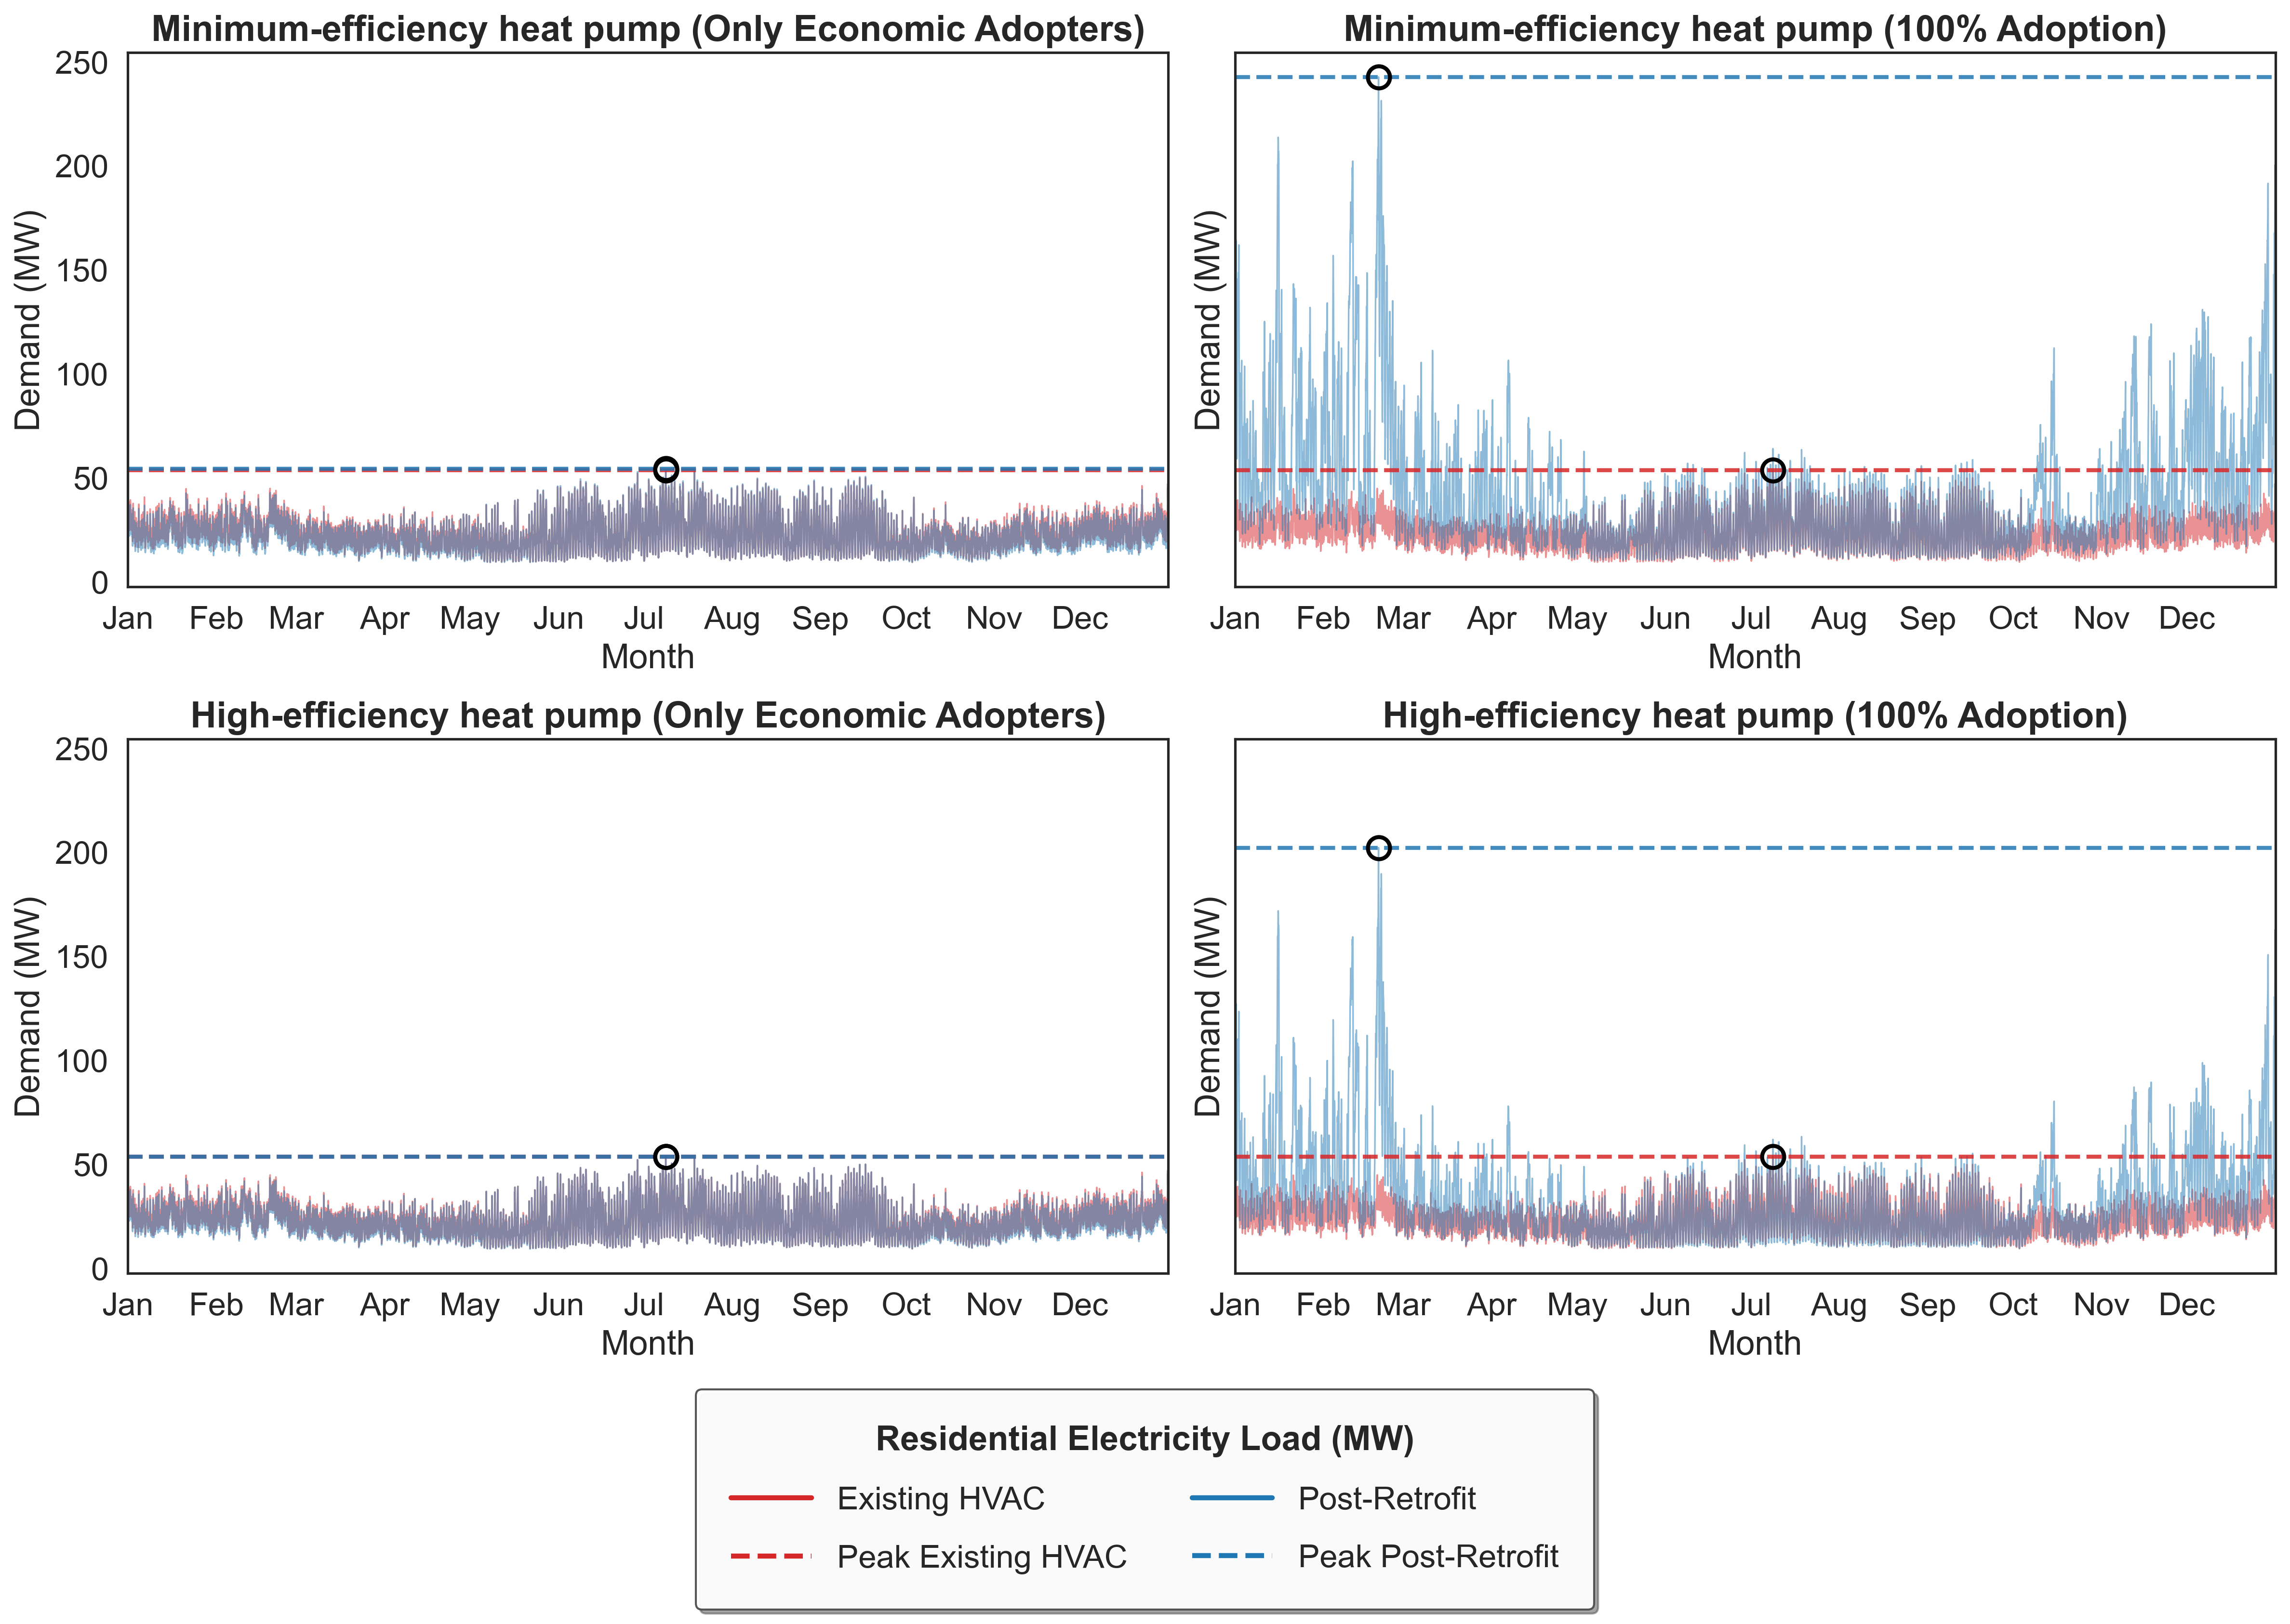

[OK] Figure saved: c:\Users\tamar\Documents\Research\cmu-tare-model\outputs\allegheny_demand_profiles_100pct_MP3_4.png


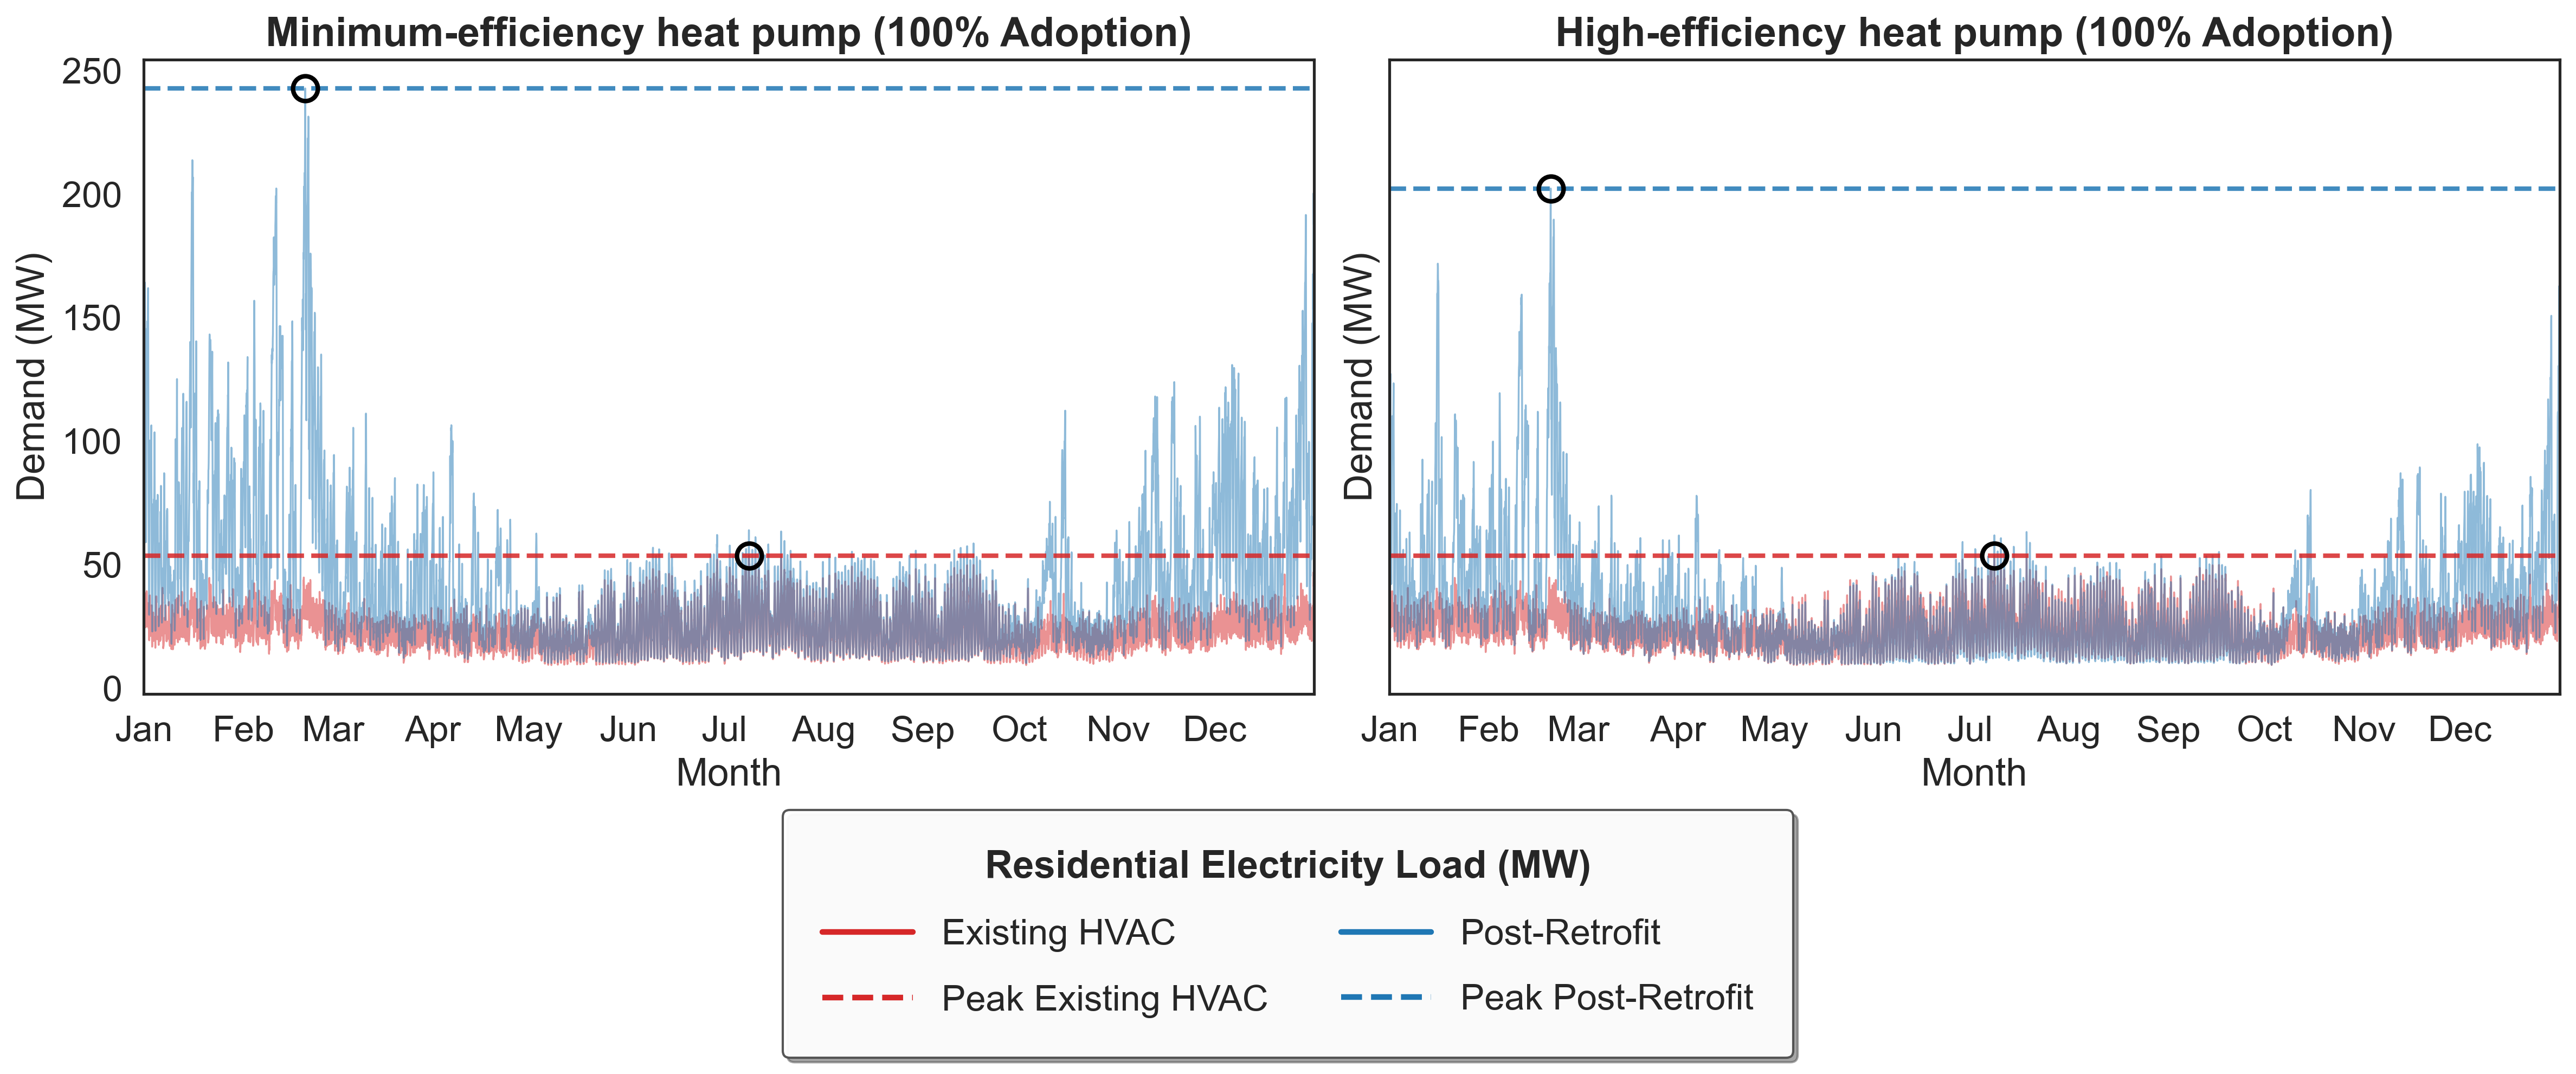

In [24]:
# ============================================================================
# GRID IMPACT -- plot county-level demand for the selected measure packages
# ============================================================================
if GRID_IMPACT_ANALYSIS:

    # ---------- Step 7: Compute scenario profiles ----------
    peak_results_case_study_by_mp = {}
    df_profiles_by_mp = {}

    # Echoed here so the printed peak numbers below are traceable to exactly
    # which NPV case and weighting mode produced them.
    print(f"Grid impact base case (constrained adopters): {BASE_CASE_NPV_CASE}")
    print(f"Custom weighting: {CUSTOM_WEIGHTING}")        

    for mp in selected_mps:
        print(
            f"\nComputing county profiles for MP{mp} "
            f"(adopter column: {adoption_col_by_mp[mp]})..."
        )

        # TODO: For loop for different NPV cases
        # NPV_CASES_CATEGORIES defined in column_names.py
        # NPV_CASE_CATEGORIES = (
        #     "heatingSavings_coolingLCC_sub",
        #     "heatingSavings_coolingLCC_unsub",
        #     "heatingSavings_coolingLCC_sub_june2026",
        #     "heatingLCC_coolingSavings_sub",
        #     "heatingLCC_coolingSavings_unsub",
        #     "heatingLCC_coolingSavings_sub_june2026",
        #     "heatingLCC_coolingLCC_sub",
        #     "heatingLCC_coolingLCC_unsub",
        #     "heatingLCC_coolingLCC_sub_june2026",
        # )
        # for 

        if CUSTOM_WEIGHTING:
            # The matched subset can span more than one real county (it
            # currently spans two, in Colorado), so adopter IDs are gathered
            # across every county in adopter_ids_by_mp rather than one FIPS
            # lookup, then narrowed to just the buildings the weight dict
            # covers.
            case_study_bldg_id_set = set(case_study_weight_dict.keys())
            constrained_ids = set()
            for county_adopters in adopter_ids_by_mp[mp].values():
                constrained_ids |= (
                    set(county_adopters["constrained"]) & case_study_bldg_id_set
                )
            case_study_adopter_ids = {
                "all_filtered": sorted(case_study_bldg_id_set),
                "constrained": sorted(constrained_ids),
            }
        else:
            # Default mode: the one county chosen earlier already has its
            # adopter IDs precomputed in adopter_ids_by_mp.
            case_study_adopter_ids = adopter_ids_by_mp[mp][case_study_fips]

        # 100pct: every building in scope adopts the retrofit -- the upper
        # bound on the demand-side impact.
        df_profile_100pct, peak_100pct = compute_county_scenario_profile(
            df_ts_baseline_case_study,
            df_ts_upgrade_case_study_by_mp[mp],
            adopter_bldg_ids=case_study_adopter_ids["all_filtered"],
            custom_weighting=CUSTOM_WEIGHTING,
            weight_dict=case_study_weight_dict,
        )

        # constrained: only the buildings where the heat pump is an economic
        # adopter (NPV >= 0) actually switch.
        df_profile_constrained, peak_constrained = compute_county_scenario_profile(
            df_ts_baseline_case_study,
            df_ts_upgrade_case_study_by_mp[mp],
            adopter_bldg_ids=case_study_adopter_ids["constrained"],
            custom_weighting=CUSTOM_WEIGHTING,
            weight_dict=case_study_weight_dict,
        )

        peak_results_case_study_by_mp[mp] = {
            "100pct": peak_100pct,
            "constrained": peak_constrained,
        }
        df_profiles_by_mp[mp] = {
            "100pct": df_profile_100pct,
            "constrained": df_profile_constrained,
        }

        print(f"\nCase-study peak results (MP{mp})")
        for scenario, peak_summary in peak_results_case_study_by_mp[mp].items():
            print(
                f"  [{scenario}] adopters: {peak_summary['n_adopters']:,d} / "
                f"{peak_summary['n_total_buildings']:,d}"
            )
            print(
                f"    adoption      : {peak_summary['pct_adopters']:.1f}%"
            )
            print(
                f"    baseline peak : {peak_summary['baseline_peak_mw']:.2f} MW "
                f"@ hour {peak_summary['peak_hour_baseline']}"
            )
            print(
                f"    scenario peak : {peak_summary['scenario_peak_mw']:.2f} MW "
                f"@ hour {peak_summary['peak_hour_scenario']}"
            )
            print(f"    delta         : {peak_summary['delta_mw']:+.2f} MW")

        # Both profiles must cover a full year of hours -- guards against a
        # silent partial-year query slipping through to the figure below.
        assert len(df_profile_100pct) == 8760
        assert len(df_profile_constrained) == 8760

    print(
        f"\n[OK] Step 7 PASSED -- peak_results_case_study_by_mp.keys() = "
        f"{list(peak_results_case_study_by_mp.keys())}"
    )

    # ---------- Demand-profile figures ----------
    # First the grid with one row per measure package (economic adopters and
    # 100% adoption), then one row with 100% adoption only.
    plot_county_demand_grid(
        df_profiles_by_mp,
        peak_results_case_study_by_mp,
        selected_mps,
        save_figure=SAVE_FIGURES,
        output_dir=PROJECT_ROOT,
        figure_dpi=FIGURE_DPI,
    )
    # The one-row figure is shorter, so more of its height goes to the legend.
    plot_county_demand_grid(
        df_profiles_by_mp,
        peak_results_case_study_by_mp,
        selected_mps,
        panels=[(mp, "100pct") for mp in selected_mps],
        subplot_positions=[(0, column) for column in range(len(selected_mps))],
        figure_size=(16, 6.5),
        legend_space=0.21,
        save_figure=SAVE_FIGURES,
        output_dir=PROJECT_ROOT,
        output_filename=(
            "allegheny_demand_profiles_100pct_MP"
            f"{'_'.join(str(mp) for mp in selected_mps)}.png"
        ),
        figure_dpi=FIGURE_DPI,
    )


Grid impact base case (constrained adopters): heatingLCC_coolingLCC_unsub
Custom weighting: True

Computing county profiles for MP3 (adopter column: ref2025_mp3_heatingLCC_coolingLCC_unsub_econ_adopter_fixed_base)...

Case-study peak results (MP3)
  [100pct] adopters: 78 / 78
    Percent adoption      : 100.0%
    Baseline absolute peak : 53.56 MW @ hour 4530
    Scenario absolute peak : 242.74 MW @ hour 1210
    Absolute peak delta    : +189.17 MW
    Baseline winter peak : 47.03 MW @ hour 8756
    Scenario winter peak : 242.74 MW @ hour 1210
    Winter peak delta    : +195.71 MW
    Baseline summer peak : 53.56 MW @ hour 4530
    Scenario summer peak : 63.99 MW @ hour 4530
    Summer peak delta    : +10.43 MW
    Baseline annual MWh : 204,560
    Scenario annual MWh : 367,325
    Annual MWh delta    : +162,764
  [constrained] adopters: 9 / 78
    Percent adoption      : 11.5%
    Baseline absolute peak : 53.56 MW @ hour 4530
    Scenario absolute peak : 54.33 MW @ hour 4530
    Absol

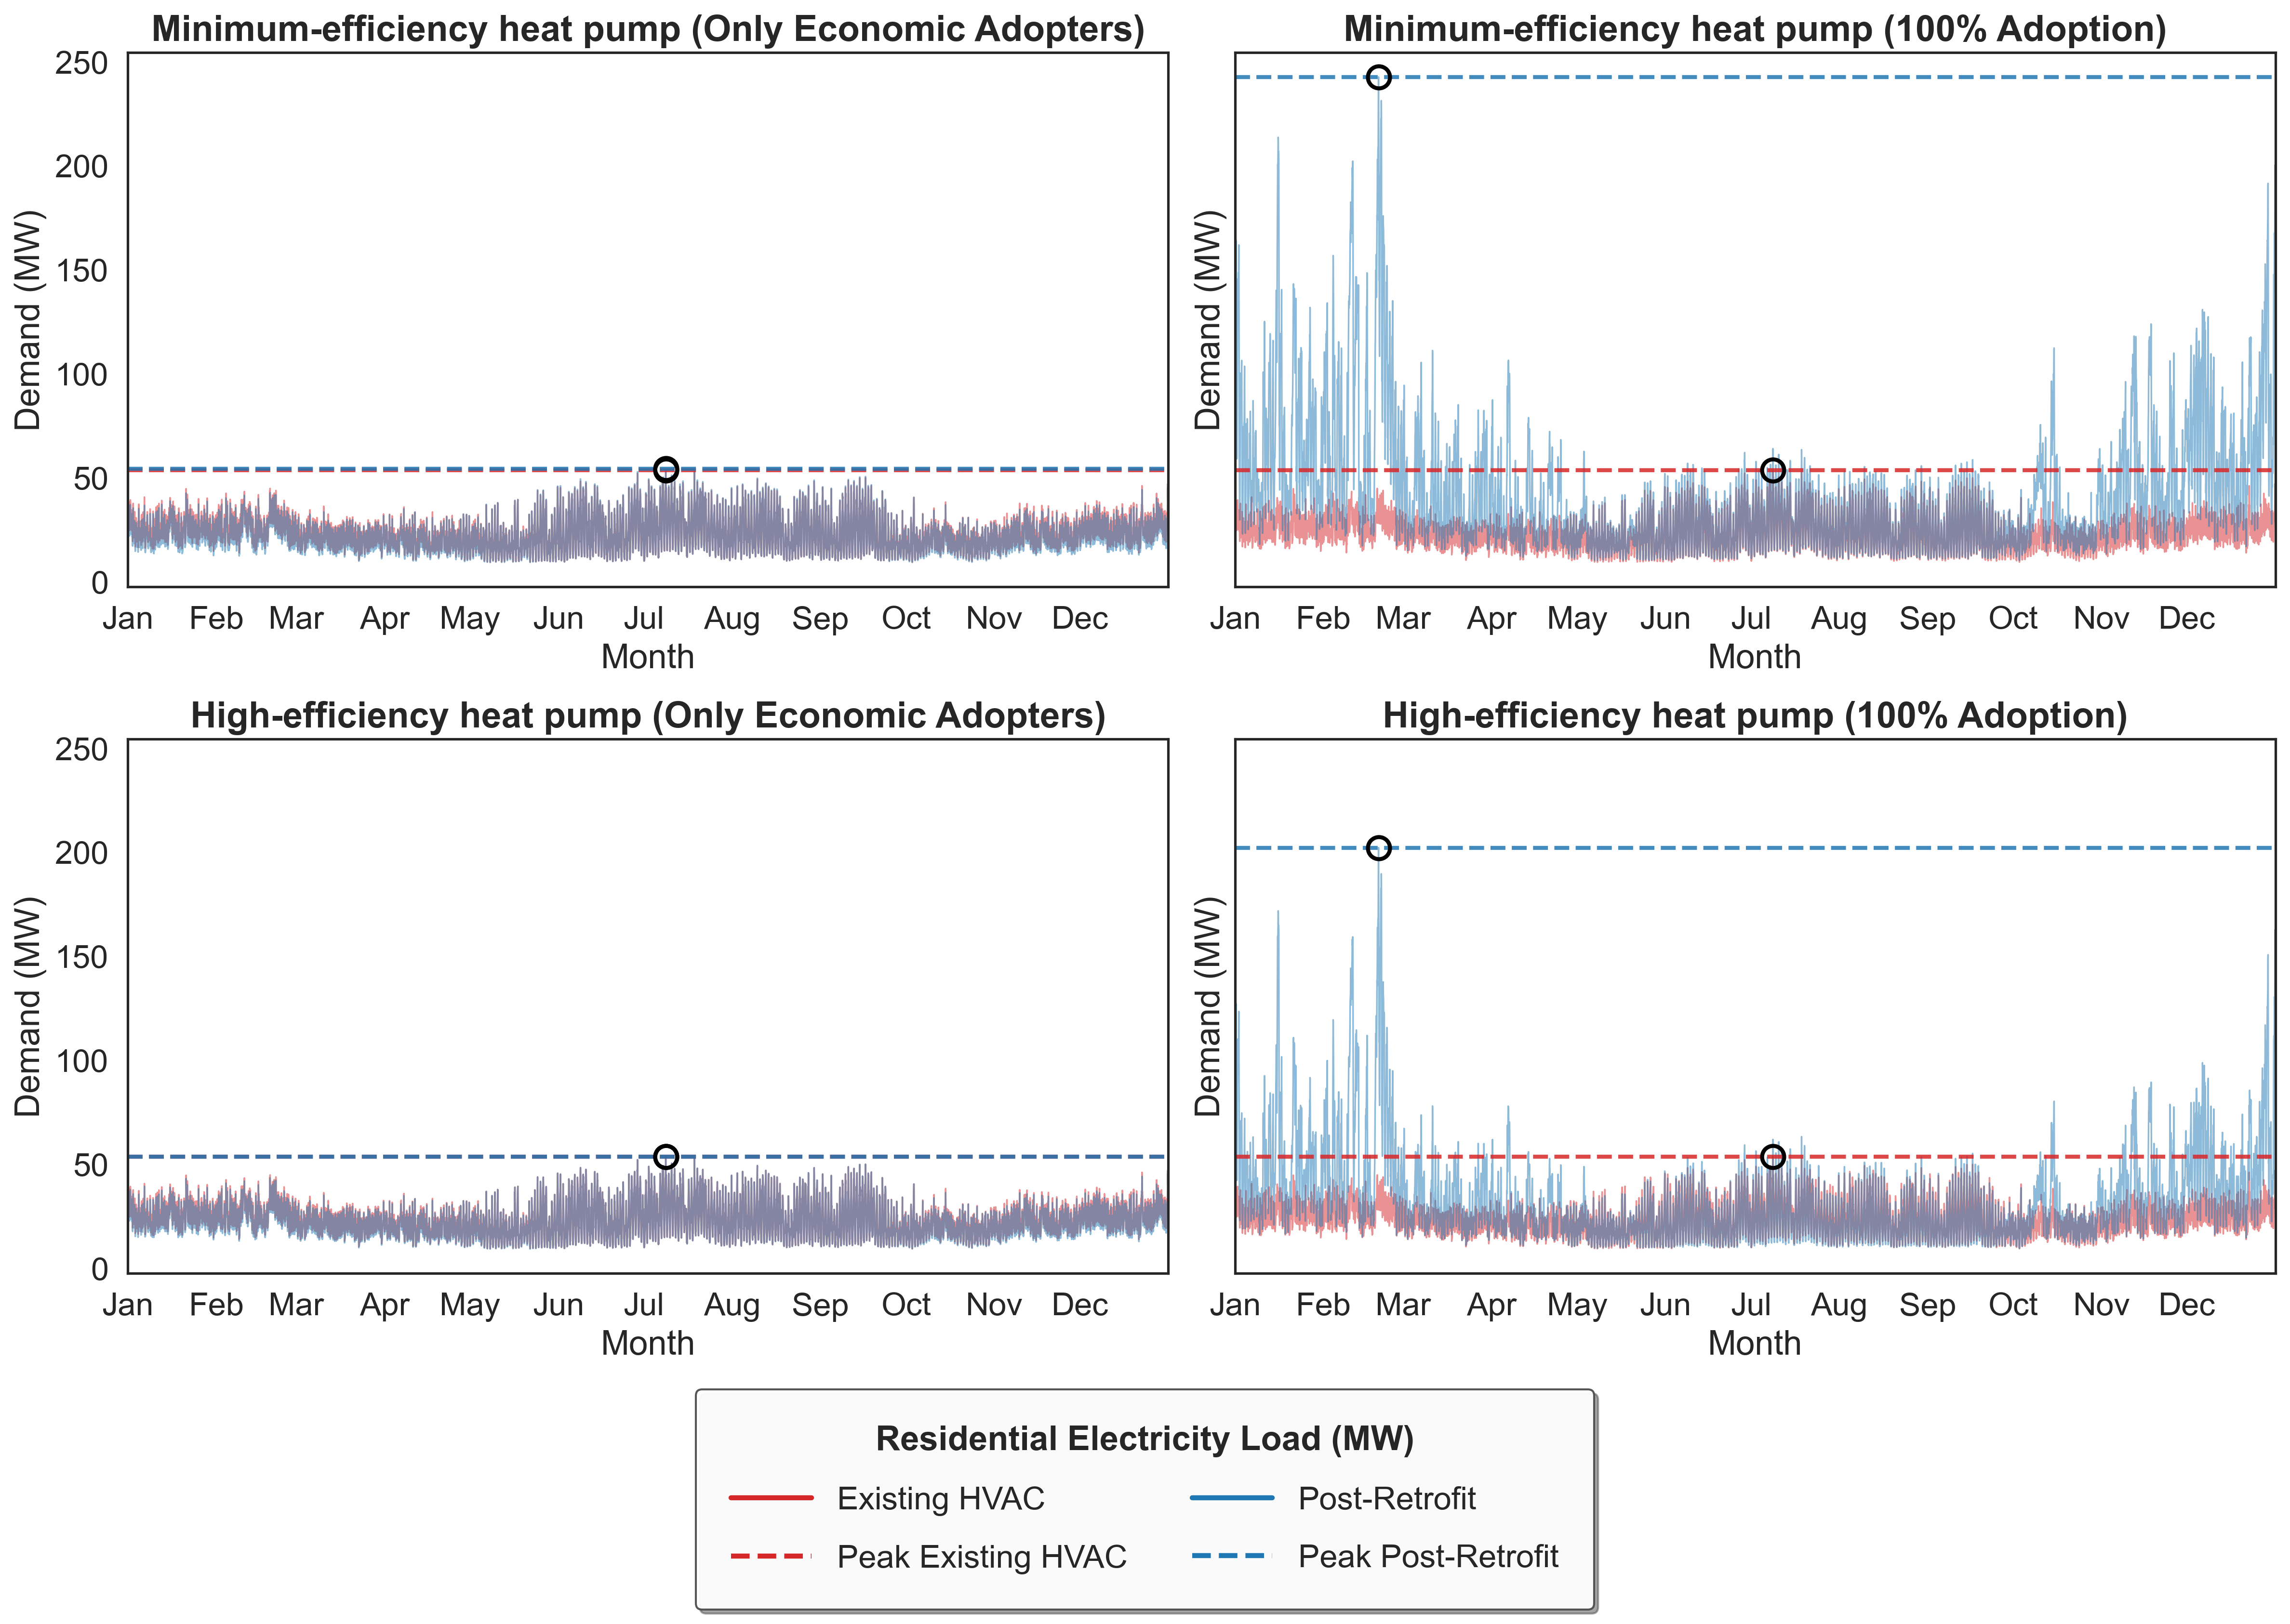

In [25]:
#Summary of peak load and annual mwh for 100% and constrained scenarios,
#Includes seasonal peaks 

if GRID_IMPACT_ANALYSIS:
 
    # ---------- Step 7: Compute scenario profiles ----------
    peak_results_case_study_by_mp = {}
    df_profiles_by_mp = {}
 
    # Echoed here so the printed peak numbers below are traceable to exactly
    # which NPV case and weighting mode produced them.
    print(f"Grid impact base case (constrained adopters): {BASE_CASE_NPV_CASE}")
    print(f"Custom weighting: {CUSTOM_WEIGHTING}")
 
    for mp in selected_mps:
        print(
            f"\nComputing county profiles for MP{mp} "
            f"(adopter column: {adoption_col_by_mp[mp]})..."
        )
 
        # TODO: For loop for different NPV cases
        # NPV_CASES_CATEGORIES defined in column_names.py
        # NPV_CASE_CATEGORIES = (
        #     "heatingSavings_coolingLCC_sub",
        #     "heatingSavings_coolingLCC_unsub",
        #     "heatingSavings_coolingLCC_sub_june2026",
        #     "heatingLCC_coolingSavings_sub",
        #     "heatingLCC_coolingSavings_unsub",
        #     "heatingLCC_coolingSavings_sub_june2026",
        #     "heatingLCC_coolingLCC_sub",
        #     "heatingLCC_coolingLCC_unsub",
        #     "heatingLCC_coolingLCC_sub_june2026",
        # )
        
 
        if CUSTOM_WEIGHTING:
            # The matched subset can span more than one real county so adopter IDs are gathered
            # across every county in adopter_ids_by_mp rather than one FIPS
            # lookup, then narrowed to just the buildings the weight dict
            case_study_bldg_id_set = set(case_study_weight_dict.keys())
            constrained_ids = set()
            for county_adopters in adopter_ids_by_mp[mp].values():
                constrained_ids |= (
                    set(county_adopters["constrained"]) & case_study_bldg_id_set
                )
            case_study_adopter_ids = {
                "all_filtered": sorted(case_study_bldg_id_set),
                "constrained": sorted(constrained_ids),
            }
        else:
            # Default mode: the one county chosen earlier already has its
            # adopter IDs precomputed in adopter_ids_by_mp.
            case_study_adopter_ids = adopter_ids_by_mp[mp][case_study_fips]
 
        # 100pct: every building in scope adopts the retrofit -- the upper
        # bound on the demand-side impact.
        df_profile_100pct, peak_100pct = compute_county_scenario_profile_seasonal(
            df_ts_baseline_case_study,
            df_ts_upgrade_case_study_by_mp[mp],
            adopter_bldg_ids=case_study_adopter_ids["all_filtered"],
            custom_weighting=CUSTOM_WEIGHTING,
            weight_dict=case_study_weight_dict,
        )
 
        # constrained: only the buildings where the heat pump is an economic
        # adopter (NPV >= 0) actually switch.
        df_profile_constrained, peak_constrained = compute_county_scenario_profile_seasonal(
            df_ts_baseline_case_study,
            df_ts_upgrade_case_study_by_mp[mp],
            adopter_bldg_ids=case_study_adopter_ids["constrained"],
            custom_weighting=CUSTOM_WEIGHTING,
            weight_dict=case_study_weight_dict,
        )
 
        peak_results_case_study_by_mp[mp] = {
            "100pct": peak_100pct,
            "constrained": peak_constrained,
        }
        df_profiles_by_mp[mp] = {
            "100pct": df_profile_100pct,
            "constrained": df_profile_constrained,
        }
 
        print(f"\nCase-study peak results (MP{mp})")
        for scenario, peak_summary in peak_results_case_study_by_mp[mp].items():
            print(
                f"  [{scenario}] adopters: {peak_summary['n_adopters']:,d} / "
                f"{peak_summary['n_total_buildings']:,d}"
            )
            print(
                f"    Percent adoption      : {peak_summary['pct_adopters']:.1f}%"
            )
            # Annual (absolute) peak: top level of the peak dict.
            print(
                f"    Baseline absolute peak : {peak_summary['baseline_peak_mw']:.2f} MW "
                f"@ hour {peak_summary['peak_hour_baseline']}"
            )
            print(
                f"    Scenario absolute peak : {peak_summary['scenario_peak_mw']:.2f} MW "
                f"@ hour {peak_summary['peak_hour_scenario']}"
            )
            print(f"    Absolute peak delta    : {peak_summary['delta_mw']:+.2f} MW")
 
            # Seasonal peaks: one nested dict per season in SEASONS.
            for season in SEASONS:
                s = peak_summary[season]
                print(
                    f"    Baseline {season} peak : {s['baseline_peak_mw']:.2f} MW "
                    f"@ hour {s['peak_hour_baseline']}"
                )
                print(
                    f"    Scenario {season} peak : {s['scenario_peak_mw']:.2f} MW "
                    f"@ hour {s['peak_hour_scenario']}"
                )
                print(f"    {season.capitalize()} peak delta    : {s['delta_mw']:+.2f} MW")
 
            # Annual energy.
            print(f"    Baseline annual MWh : {peak_summary['baseline_mwh']:,.0f}")
            print(f"    Scenario annual MWh : {peak_summary['scenario_mwh']:,.0f}")
            print(f"    Annual MWh delta    : {peak_summary['delta_mwh']:+,.0f}")
 
        # Both profiles must cover a full year of hours -- guards against a
        # silent partial-year query slipping through to the figure below.
        assert len(df_profile_100pct) == 8760
        assert len(df_profile_constrained) == 8760
 
    print(
        f"\n[OK] Step 7 PASSED -- peak_results_case_study_by_mp.keys() = "
        f"{list(peak_results_case_study_by_mp.keys())}"
    )
 
    # ---------- Demand-profile grid figure ----------
    # plot_county_demand_grid is unchanged: it reads the annual peak keys at
    # the top level of each peak dict, which the seasonal function preserves.
    plot_county_demand_grid(
        df_profiles_by_mp,
        peak_results_case_study_by_mp,
        selected_mps,
        save_figure=SAVE_FIGURES,
        output_dir=PROJECT_ROOT,
        figure_dpi=FIGURE_DPI,
    )
 

In [26]:
import importlib
import cmu_tare_model.grid_impact.peak_load_functions as plf   # adjust to the real module path

importlib.reload(plf)

# Re-bind the names the notebook uses
from cmu_tare_model.grid_impact.peak_load_functions import (
    compute_county_scenario_profile,
    compute_county_scenario_profile_seasonal,
    peak_dicts_to_table,

)

In [27]:
# Row labels: edit these to whatever you want shown in the table.

#TODO update scenario labels for more scenarios 

scenario_labels = {"100pct": "100% Adoption", "constrained": "Economic Adopters"}
 
scenario_peaks = {
    f"MP{mp} ({scenario_labels[scenario]})": peaks
    for mp, by_scenario in peak_results_case_study_by_mp.items()
    for scenario, peaks in by_scenario.items()
}
 
df_peak_table = peak_dicts_to_table(scenario_peaks)
display(df_peak_table.round(2))          # `display` in a notebook; else print()


,scenario,Adopting Homes (%),Winter Peak (MW),Summer Peak (MW),Absolute Annual Peak (MW),Annual Consumption (GWh),Peak Delta (MW),Electricity Consumption Delta (GWh)
0,Baseline,0.00,47.03,53.56,53.56,204.56,0.00,0.00
1,MP3 (100% Adoption),100.00,242.74,63.99,242.74,367.32,189.17,162764.10
2,MP3 (Economic Adopters),11.54,45.21,54.33,54.33,195.42,0.76,-9135.62
3,MP4 (100% Adoption),100.00,202.23,63.26,202.23,286.95,148.67,82385.32
4,MP4 (Economic Adopters),10.26,45.62,53.68,53.68,196.78,0.12,-7776.40


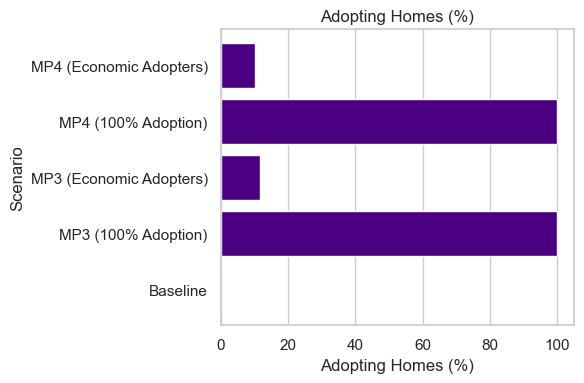

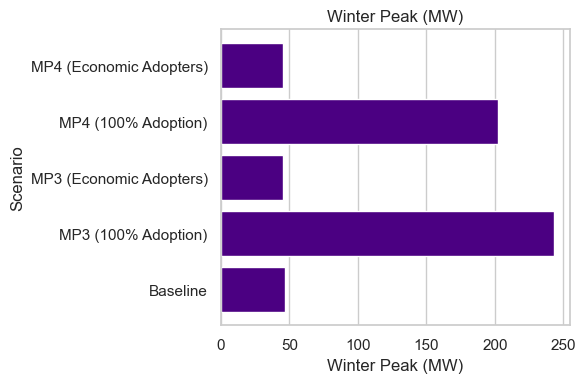

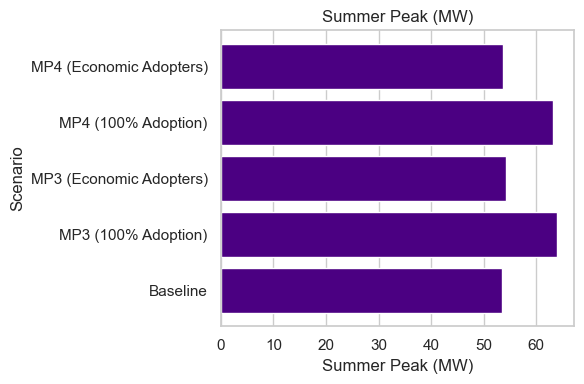

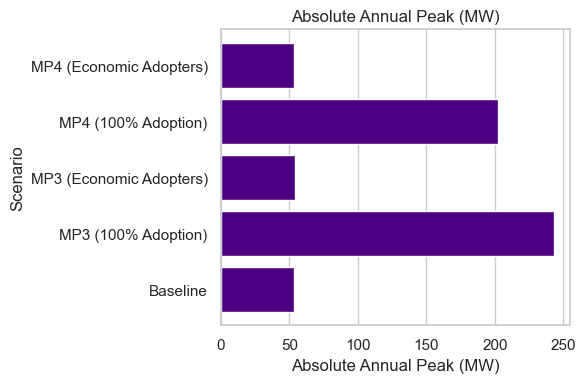

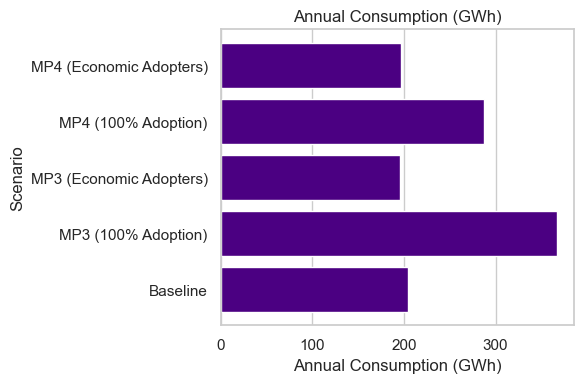

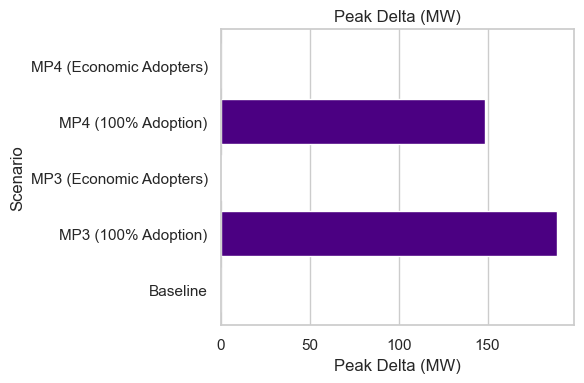

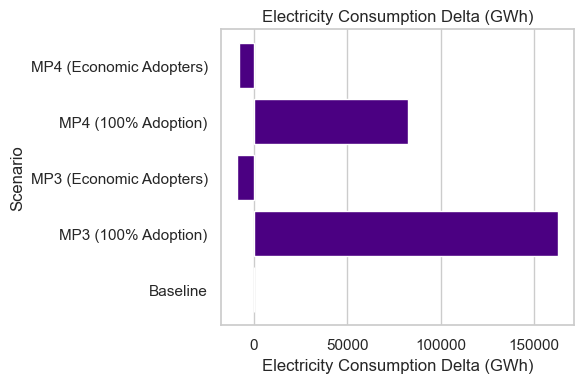

In [28]:
def plot_energy_data_by_scenario(summary_df, metric):
    fig, ax = plt.subplots(figsize=(6, 4), dpi=100)

    ax.barh(summary_df["scenario"], summary_df[metric], color="#4B0082")
    ax.set_title(metric)
    ax.set_xlabel(metric)
    ax.set_ylabel("Scenario")
    ax.grid(axis="y", visible=False)
    fig.tight_layout()
    

    
for metric in df_peak_table:
    if metric != "scenario":
        plot_energy_data_by_scenario(df_peak_table, metric)
        plt.show()

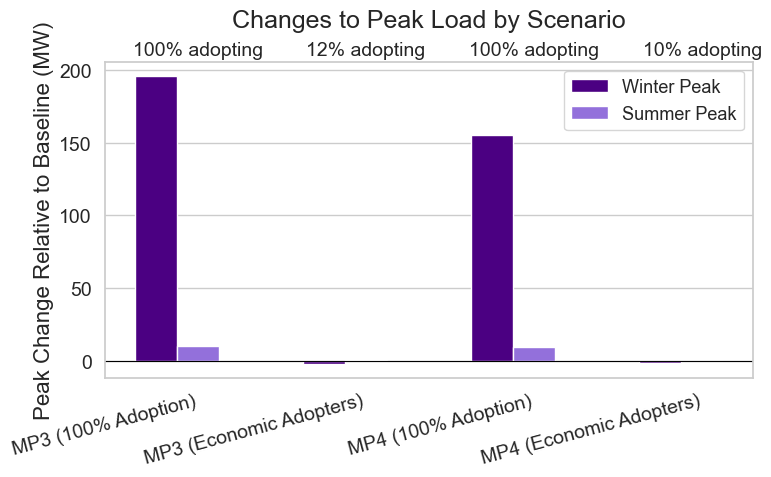

In [29]:
def plot_peak_delta_by_scenario(summary_df):


    base = summary_df[summary_df["scenario"] == "Baseline"].iloc[0]
    df = summary_df[summary_df["scenario"] != "Baseline"].reset_index(drop=True)

    peak_cols = {
        "Winter Peak": "Winter Peak (MW)",
        "Summer Peak": "Summer Peak (MW)",
        # "Annual peak": "Absolute Annual Peak (MW)",
    }
    colors = ["#4B0082", "#9370DB", "#BDB0D0"]

    #setting font sizes
    plt.rcParams.update({
        "font.size": 14,          # default for text, including legend
        "axes.titlesize": 18,
        "axes.labelsize": 16,
        "xtick.labelsize": 14,
        "ytick.labelsize": 14,    # also applies to the twinx axis
        "legend.fontsize": 13,
    })

    fig, ax = plt.subplots(figsize=(8, 5), dpi=100)
    x = np.arange(len(df))
    width = 0.25

    # One bar per peak type, offset so the three sit side by side per scenario
    for i, (label, col) in enumerate(peak_cols.items()):
        delta = df[col] - base[col]
        ax.bar(x + (i - 1) * width, delta, width, label=label, color=colors[i])

    ax.axhline(0, color="black", linewidth=0.8)

    # % adopting as text above each group (x in data units, y in axes fraction)
    for xi, pct in zip(x, df["Adopting Homes (%)"]):
        ax.text(xi, 1.01, f"{pct:.0f}% adopting",
                transform=ax.get_xaxis_transform(),
                ha="center", va="bottom", fontsize=14)

    ax.set_xticks(x)
    ax.set_xticklabels(df["scenario"], rotation=15, ha="right")
    ax.set_ylabel("Peak Change Relative to Baseline (MW)")
    ax.set_title("Changes to Peak Load by Scenario", pad=25)
    ax.legend()
    ax.grid(axis="x", visible=False)
    fig.tight_layout()


plot_peak_delta_by_scenario(df_peak_table)
plt.show()

In [30]:
#Pseudocode for custom aggregation

#1 - pull timeseries load profiles for all matched buildings for MP0, MP3, MP4

#2 - load PSM results that include building IDs for feeders, feeder-phases, and transformers

#3 - Update custom weighting to include grid topology aggregation levels

#4 - Within a loop for TARE scenarios
#    with another loop for aggregation level, determine:
#   a) winter peak
#   b) summer peak
#   c) absolute peak
#   d) peak changes
#   e) annual mWh

# Model Runtime

In [31]:
# Get the current datetime again
end_time = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")

# Calculate the elapsed time
elapsed_time = datetime.strptime(end_time, "%Y-%m-%d_%H-%M-%S") - datetime.strptime(start_time, "%Y-%m-%d_%H-%M-%S")

# Format the elapsed time
elapsed_seconds = elapsed_time.total_seconds()
elapsed_minutes = int(elapsed_seconds // 60)
elapsed_seconds = int(elapsed_seconds % 60)

# Print the elapsed time
print(f"The code took {elapsed_minutes} minutes and {elapsed_seconds} seconds to execute.")

The code took 2 minutes and 51 seconds to execute.
